##Loading the dataset

In [78]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


* Datasource is in .arff file which can't be loaded directly.
  - So, scipy library will be used to read the data source

In [79]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import arff

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)

DATA_DIR = '/content/drive/MyDrive/Y3S1ML'
FILE_PATH = os.path.join(DATA_DIR, 'Rice_Cammeo_Osmancik.arff')

print(os.listdir(DATA_DIR))
print("File exists:", os.path.exists(FILE_PATH))

['Rice_Cammeo_Osmancik.arff', 'Citation_Request.txt', 'Y3S1ML_test.ipynb', 'Copy_of_Y3S1_ML_Group_Assignment.ipynb']
File exists: True


In [80]:
data, meta = arff.loadarff(FILE_PATH)
df = pd.DataFrame(data)

# ARFF nominal attributes load as bytes (b'Cammeo'), so decode them to strings
for col in df.select_dtypes(include=[object]).columns:
    df[col] = df[col].str.decode('utf-8')

print("Loaded successfully.")

Loaded successfully.


Metadata Exploration

In [81]:
print("Relation:", meta.name)
print("Attributes (name, type):")
for name in meta.names():
    print(f"  {name:<20} {meta[name]}")

Relation: Rice_Cammeo_Osmancik
Attributes (name, type):
  Area                 ('numeric', None)
  Perimeter            ('numeric', None)
  Major_Axis_Length    ('numeric', None)
  Minor_Axis_Length    ('numeric', None)
  Eccentricity         ('numeric', None)
  Convex_Area          ('numeric', None)
  Extent               ('numeric', None)
  Class                ('nominal', ('Cammeo', 'Osmancik'))


##Dataset observations

In [82]:
print("Shape:", df.shape)
df.head(10)

Shape: (3810, 8)


,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class
0,15231.0000,525.5790,229.7499,85.0938,0.9289,15617.0000,0.5729,Cammeo
1,14656.0000,494.3110,206.0201,91.7310,0.8954,15072.0000,0.6154,Cammeo
2,14634.0000,501.1220,214.1068,87.7683,0.9121,14954.0000,0.6933,Cammeo
3,13176.0000,458.3430,193.3374,87.4484,0.8919,13368.0000,0.6407,Cammeo
4,14688.0000,507.1670,211.7434,89.3125,0.9067,15262.0000,0.6460,Cammeo
5,13479.0000,477.0160,200.0531,86.6503,0.9013,13786.0000,0.6579,Cammeo
6,15757.0000,509.2810,207.2967,98.3361,0.8803,16150.0000,0.5897,Cammeo
7,16405.0000,526.5700,221.6125,95.4367,0.9025,16837.0000,0.6589,Cammeo
8,14534.0000,483.6410,196.6508,95.0507,0.8754,14932.0000,0.6497,Cammeo
9,13485.0000,471.5700,198.2726,87.7273,0.8968,13734.0000,0.5723,Cammeo


In [83]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3810 entries, 0 to 3809
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Area               3810 non-null   float64
 1   Perimeter          3810 non-null   float64
 2   Major_Axis_Length  3810 non-null   float64
 3   Minor_Axis_Length  3810 non-null   float64
 4   Eccentricity       3810 non-null   float64
 5   Convex_Area        3810 non-null   float64
 6   Extent             3810 non-null   float64
 7   Class              3810 non-null   object 
dtypes: float64(7), object(1)
memory usage: 238.3+ KB


In [84]:
df.describe()

,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent
count,3810.0000,3810.0000,3810.0000,3810.0000,3810.0000,3810.0000,3810.0000
mean,12667.7276,454.2392,188.7762,86.3138,0.8869,12952.4969,0.6619
std,1732.3677,35.5971,17.4487,5.7298,0.0208,1776.9720,0.0772
min,7551.0000,359.1000,145.2645,59.5324,0.7772,7723.0000,0.4974
25%,11370.5000,426.1448,174.3539,82.7317,0.8724,11626.2500,0.5989
50%,12421.5000,448.8525,185.8101,86.4346,0.8891,12706.5000,0.6454
75%,13950.0000,483.6837,203.5504,90.1437,0.9026,14284.0000,0.7266
max,18913.0000,548.4460,239.0105,107.5424,0.9480,19099.0000,0.8610


In [85]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
Area                 0
Perimeter            0
Major_Axis_Length    0
Minor_Axis_Length    0
Eccentricity         0
Convex_Area          0
Extent               0
Class                0
dtype: int64

Duplicate rows: 0


Target column: Class
Class
Osmancik    2180
Cammeo      1630
Name: count, dtype: int64

Proportions:
Class
Osmancik   0.5722
Cammeo     0.4278
Name: proportion, dtype: float64


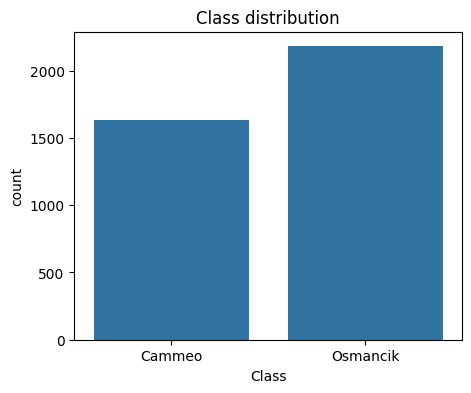

In [86]:
target_col = df.columns[-1]
print("Target column:", target_col)

counts = df[target_col].value_counts()
print(counts)
print("\nProportions:")
print(df[target_col].value_counts(normalize=True))

plt.figure(figsize=(5, 4))
sns.countplot(data=df, x=target_col)
plt.title('Class distribution')
plt.show()

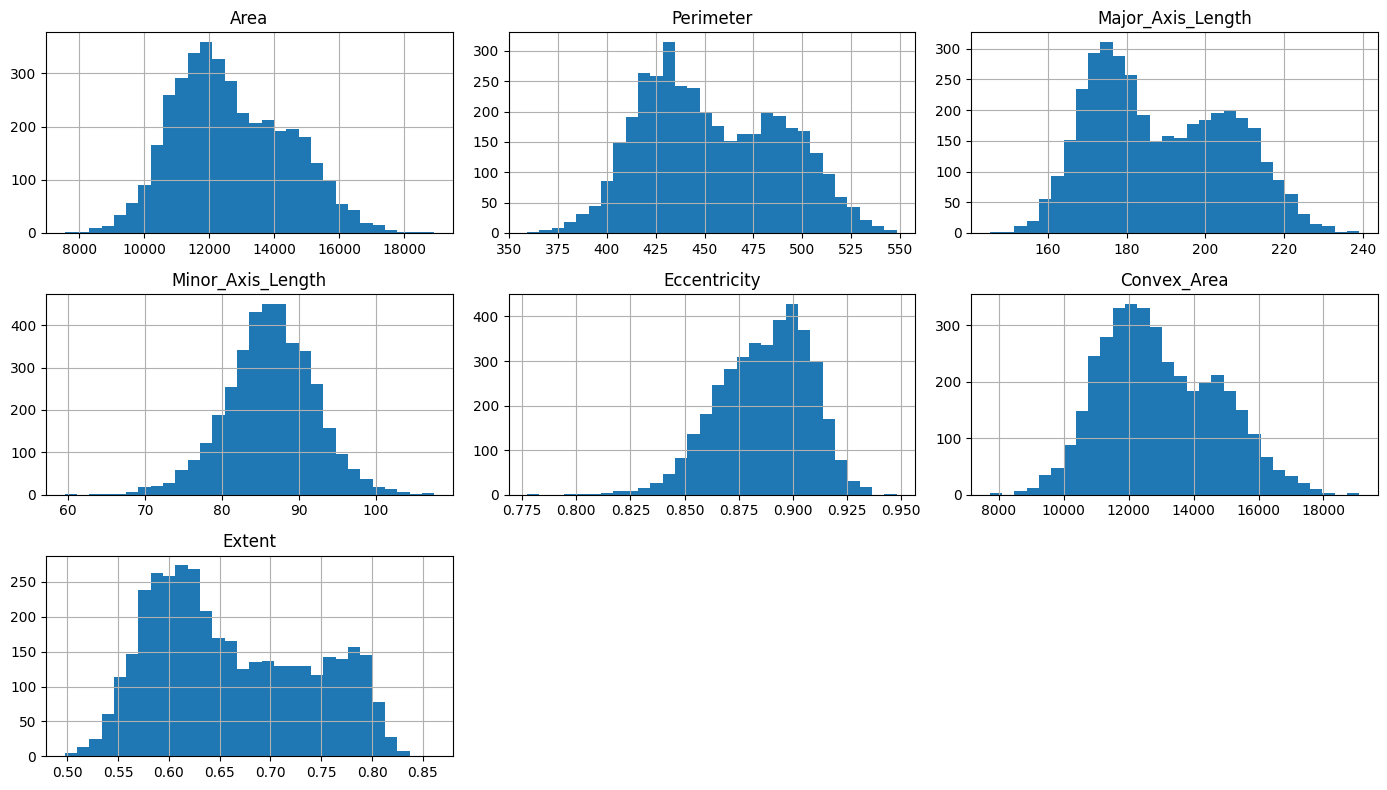

In [87]:
features = df.drop(columns=[target_col]).columns

df[features].hist(bins=30, figsize=(14, 8))
plt.tight_layout()
plt.show()

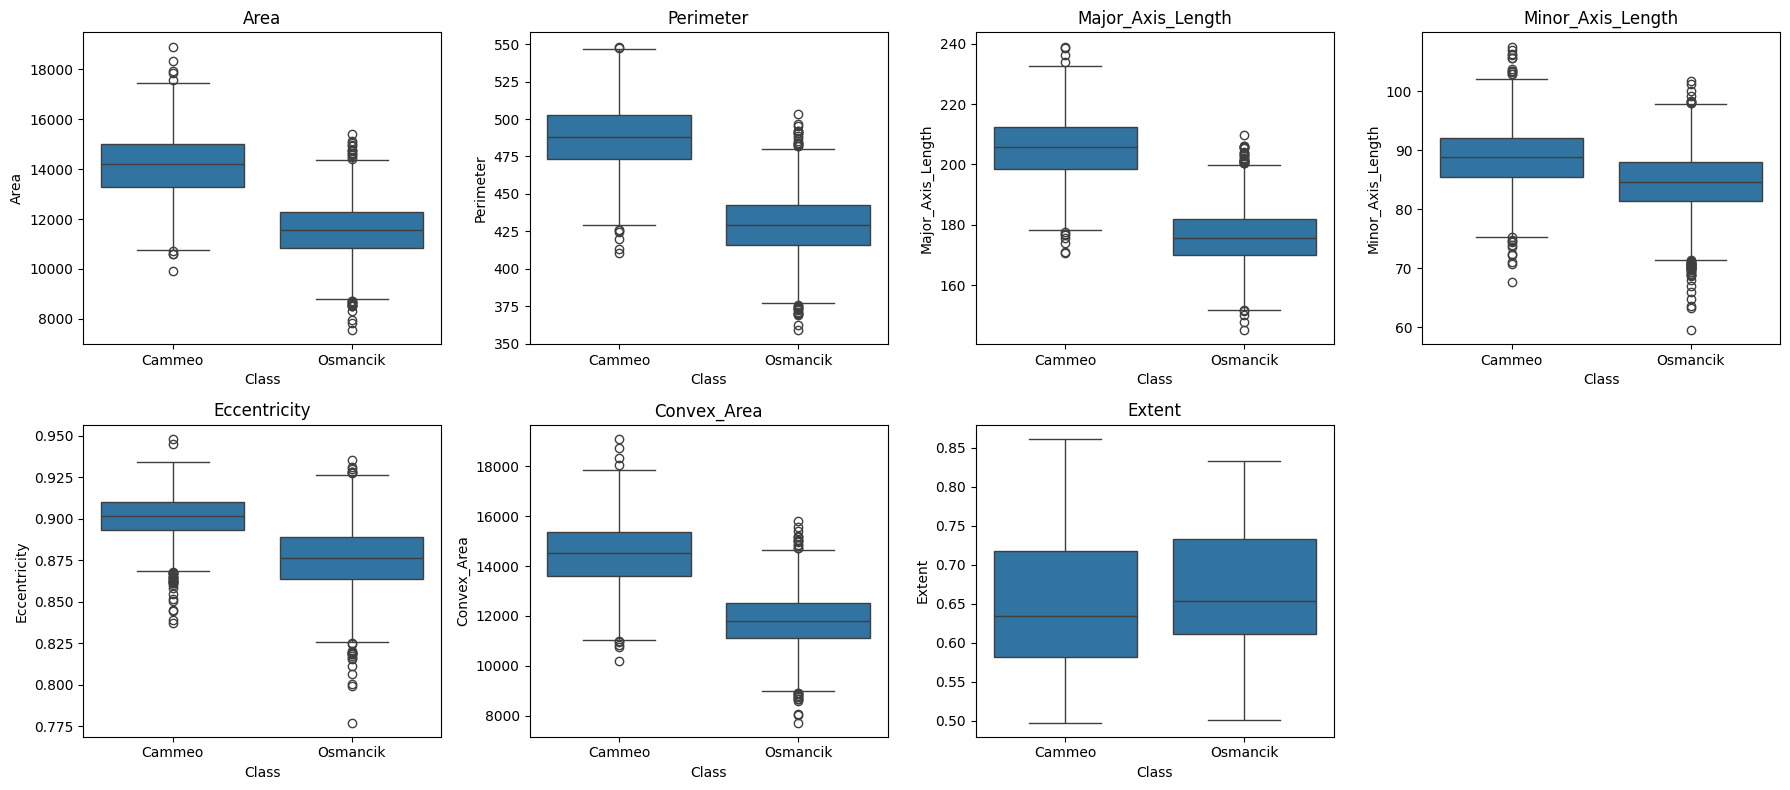

In [88]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()

for i, col in enumerate(features):
    sns.boxplot(data=df, x=target_col, y=col, ax=axes[i])
    axes[i].set_title(col)

# Hide any unused subplot
for j in range(len(features), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

#Major Dataset Observations


* Clean Dataset
  - 3,810 rows × 8 columns
  - No Nulls
  - No Duplicates
  - 7 numeric features and 1 categorical feature

* Class balance
  - 57% for Osmancik, 43% for Cammeo.
  - Mildly imbalanced

* Scale differences between features
  - Scaling is required

* Class separation (boxplots), the most important finding
  - Strongly discriminative: Area, Perimeter, Major_Axis_Length, Convex_Area
  - Weakly discriminative: Extent

* Outliers
  - Outliers appear in almost every feature

##Checking out the correlation among the features

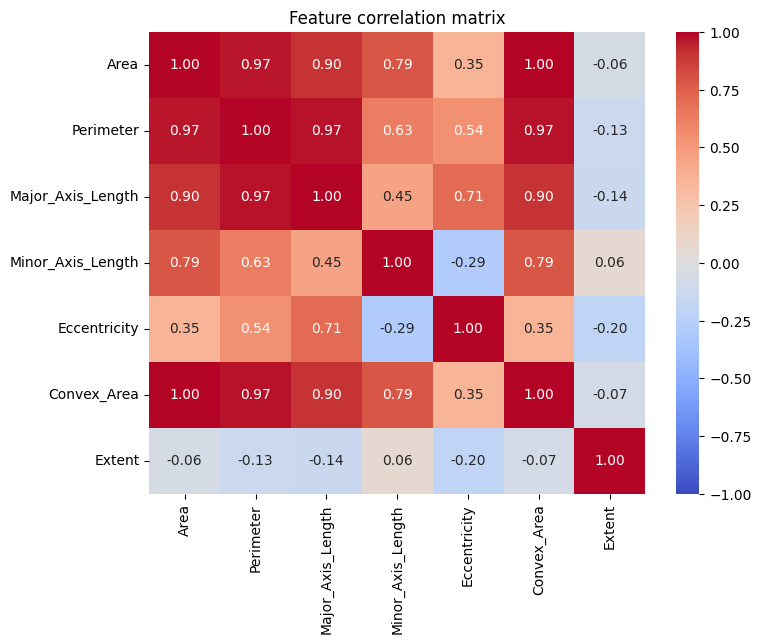

In [89]:
corr = df[features].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Feature correlation matrix')
plt.show()

* Area and Convex_Area: r = 1.00 (Same feature)
* Many features are highly correlated

##Feature Engineering

In [90]:
df_fe = df.copy()

df_fe['Aspect_Ratio'] = df_fe['Major_Axis_Length'] / df_fe['Minor_Axis_Length']
df_fe['Compactness']  = (4 * np.pi * df_fe['Area']) / (df_fe['Perimeter'] ** 2)
df_fe['Solidity']     = df_fe['Area'] / df_fe['Convex_Area']

new_feats = ['Aspect_Ratio', 'Compactness', 'Solidity']

###New Features

  - Aspect_Ratio = Major_Axis_Length / Minor_Axis_Length
  - Compactness = (4π × Area) / Perimeter²
  - Solidity = Area / Convex_Area

In [91]:
print("NaN / inf check:")
print(df_fe[new_feats].isnull().sum())
print("Inf values:", np.isinf(df_fe[new_feats]).sum().sum())

df_fe[new_feats].describe().T

NaN / inf check:
Aspect_Ratio    0
Compactness     0
Solidity        0
dtype: int64
Inf values: 0


,count,mean,std,min,25%,50%,75%,max
Aspect_Ratio,3810.0000,2.1908,0.1895,1.5893,2.0459,2.1843,2.3229,3.1422
Compactness,3810.0000,0.7698,0.0330,0.6203,0.7461,0.7698,0.7940,0.9027
Solidity,3810.0000,0.9781,0.0061,0.9263,0.9743,0.9788,0.9828,0.9903


In [92]:
drop_cols = ['Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length',
             'Eccentricity', 'Convex_Area']

df_fe = df_fe.drop(columns=drop_cols)

final_features = [c for c in df_fe.columns if c != target_col]
print("Final features:", final_features)
df_fe.head()

Final features: ['Area', 'Extent', 'Aspect_Ratio', 'Compactness', 'Solidity']


,Area,Extent,Class,Aspect_Ratio,Compactness,Solidity
0,15231.0000,0.5729,Cammeo,2.7000,0.6929,0.9753
1,14656.0000,0.6154,Cammeo,2.2459,0.7537,0.9724
2,14634.0000,0.6933,Cammeo,2.4395,0.7323,0.9786
3,13176.0000,0.6407,Cammeo,2.2109,0.7882,0.9856
4,14688.0000,0.6460,Cammeo,2.3708,0.7176,0.9624


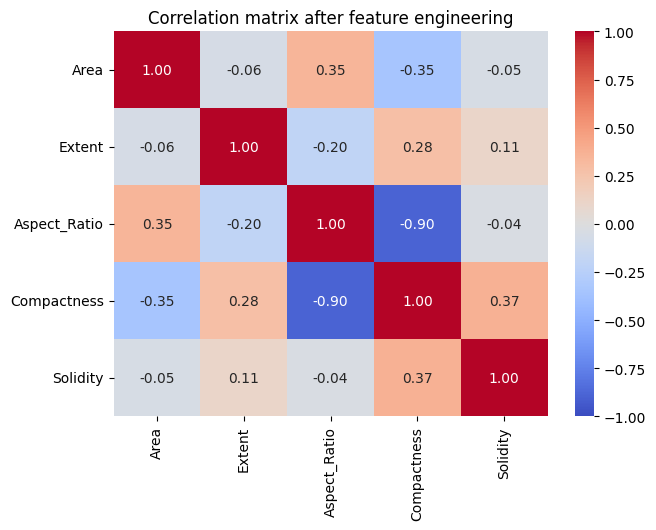

In [93]:
corr_new = df_fe[final_features].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr_new, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation matrix after feature engineering')
plt.show()

Final observation: Still correlated

In [94]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

X_vif = add_constant(df_fe[final_features])

vif = pd.DataFrame({
    'Feature': final_features,
    'VIF': [variance_inflation_factor(X_vif.values, i + 1)
            for i in range(len(final_features))]
})
vif

,Feature,VIF
0,Area,1.1490
1,Extent,1.1252
2,Aspect_Ratio,10.9676
3,Compactness,13.2164
4,Solidity,2.4549


###Trying different features

In [95]:
df_v2 = df.copy()

df_v2['Perimeter_Area_Ratio'] = df_v2['Perimeter'] / df_v2['Area']

df_v2['Compactness'] = df_v2['Area'] / (df_v2['Major_Axis_Length'] * df_v2['Minor_Axis_Length'])

* Compactness = Area / (Major_Axis_Length × Minor_Axis_Length)
* Perimeter_Area_Ratio = Perimeter / Area

In [96]:
keep_cols = ['Eccentricity', 'Extent', 'Compactness', 'Perimeter_Area_Ratio']

df_v2 = df_v2[keep_cols + [target_col]]
final_features_v2 = keep_cols

print("Final features:", final_features_v2)
df_v2.head()

Final features: ['Eccentricity', 'Extent', 'Compactness', 'Perimeter_Area_Ratio']


,Eccentricity,Extent,Compactness,Perimeter_Area_Ratio,Class
0,0.9289,0.5729,0.7791,0.0345,Cammeo
1,0.8954,0.6154,0.7755,0.0337,Cammeo
2,0.9121,0.6933,0.7787,0.0342,Cammeo
3,0.8919,0.6407,0.7793,0.0348,Cammeo
4,0.9067,0.6460,0.7767,0.0345,Cammeo


In [97]:
print("Missing values:\n", df_v2[final_features_v2].isnull().sum())
print("Inf values:", np.isinf(df_v2[final_features_v2]).sum().sum())

df_v2[final_features_v2].describe().T

Missing values:
 Eccentricity            0
Extent                  0
Compactness             0
Perimeter_Area_Ratio    0
dtype: int64
Inf values: 0


,count,mean,std,min,25%,50%,75%,max
Eccentricity,3810.0000,0.8869,0.0208,0.7772,0.8724,0.8891,0.9026,0.9480
Extent,3810.0000,0.6619,0.0772,0.4974,0.5989,0.6454,0.7266,0.8610
Compactness,3810.0000,0.7753,0.0040,0.7580,0.7729,0.7756,0.7780,0.7839
Perimeter_Area_Ratio,3810.0000,0.0362,0.0023,0.0286,0.0345,0.0361,0.0376,0.0489


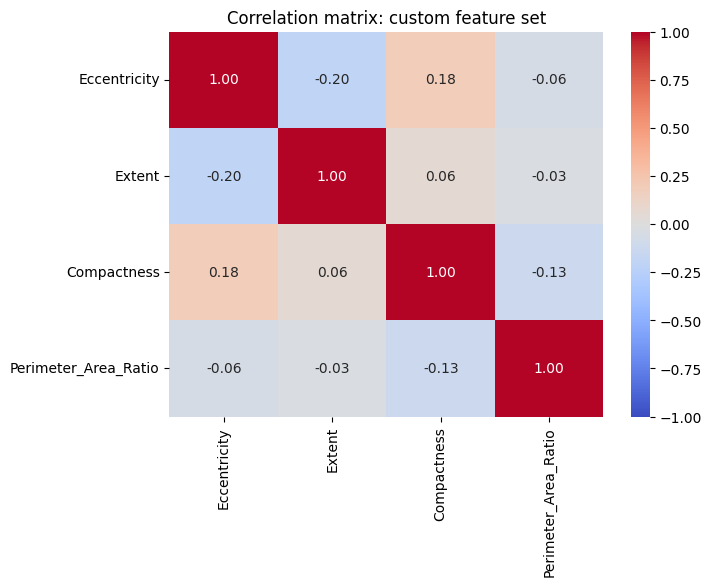

In [98]:
corr_v2 = df_v2[final_features_v2].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr_v2, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation matrix: custom feature set')
plt.show()

Observation: Split ready

In [99]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

X_vif_v2 = add_constant(df_v2[final_features_v2])

vif_v2 = pd.DataFrame({
    'Feature': final_features_v2,
    'VIF': [variance_inflation_factor(X_vif_v2.values, i + 1)
            for i in range(len(final_features_v2))]
})
vif_v2

,Feature,VIF
0,Eccentricity,1.0855
1,Extent,1.0517
2,Compactness,1.0594
3,Perimeter_Area_Ratio,1.0200


##Encoding

In [100]:
X = df_v2[final_features_v2].copy()
y_raw = df_v2[target_col].copy()

print("X shape:", X.shape)
print("Target classes:", y_raw.unique())

X shape: (3810, 4)
Target classes: ['Cammeo' 'Osmancik']


In [101]:
#Encoding the target
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y = le.fit_transform(y_raw)

print("Class mapping:", dict(zip(le.classes_, le.transform(le.classes_))))
print("y shape:", y.shape)

Class mapping: {'Cammeo': np.int64(0), 'Osmancik': np.int64(1)}
y shape: (3810,)


###Cammeo: 0, Osmancik: 1

##80%-20% Train Test data split

In [102]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (3048, 4) | Test: (762, 4)


In [103]:
split_summary = pd.DataFrame({
    'Overall': np.bincount(y) / len(y),
    'Train':   np.bincount(y_train) / len(y_train),
    'Test':    np.bincount(y_test) / len(y_test)
}, index=le.classes_)

split_summary

,Overall,Train,Test
Cammeo,0.4278,0.4278,0.4278
Osmancik,0.5722,0.5722,0.5722


In [104]:
print("Train class counts:", dict(zip(le.classes_, np.bincount(y_train))))
print("Test class counts :", dict(zip(le.classes_, np.bincount(y_test))))

Train class counts: {'Cammeo': np.int64(1304), 'Osmancik': np.int64(1744)}
Test class counts : {'Cammeo': np.int64(326), 'Osmancik': np.int64(436)}


##Data Scaling

In [105]:
skew_kurt = pd.DataFrame({
    'Skewness': X_train.skew(),
    'Kurtosis': X_train.kurt()
})

def skew_level(s):
    s = abs(s)
    if s < 0.5:
        return 'Symmetric'
    elif s < 1:
        return 'Moderate'
    return 'High'

skew_kurt['Skew_Level'] = skew_kurt['Skewness'].apply(skew_level)
skew_kurt

,Skewness,Kurtosis,Skew_Level
Eccentricity,-0.4552,0.0897,Symmetric
Extent,0.3264,-1.0573,Symmetric
Compactness,-0.5481,0.3529,Moderate
Perimeter_Area_Ratio,0.3852,0.6008,Symmetric


In [106]:
def iqr_outlier_summary(data):
    rows = []
    for col in data.columns:
        q1, q3 = data[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_low  = (data[col] < lower).sum()
        n_high = (data[col] > upper).sum()
        rows.append({
            'Feature': col,
            'Lower_Bound': lower,
            'Upper_Bound': upper,
            'Low_Outliers': n_low,
            'High_Outliers': n_high,
            'Total_Outliers': n_low + n_high,
            'Outlier_%': 100 * (n_low + n_high) / len(data)
        })
    return pd.DataFrame(rows).set_index('Feature')

outlier_summary = iqr_outlier_summary(X_train)
outlier_summary

,Lower_Bound,Upper_Bound,Low_Outliers,High_Outliers,Total_Outliers,Outlier_%
Feature,,,,,,
Eccentricity,0.8255,0.9487,14,0,14,0.4593
Extent,0.4051,0.9219,0,0,0,0.0000
Compactness,0.7650,0.7859,40,0,40,1.3123
Perimeter_Area_Ratio,0.0299,0.0422,3,34,37,1.2139


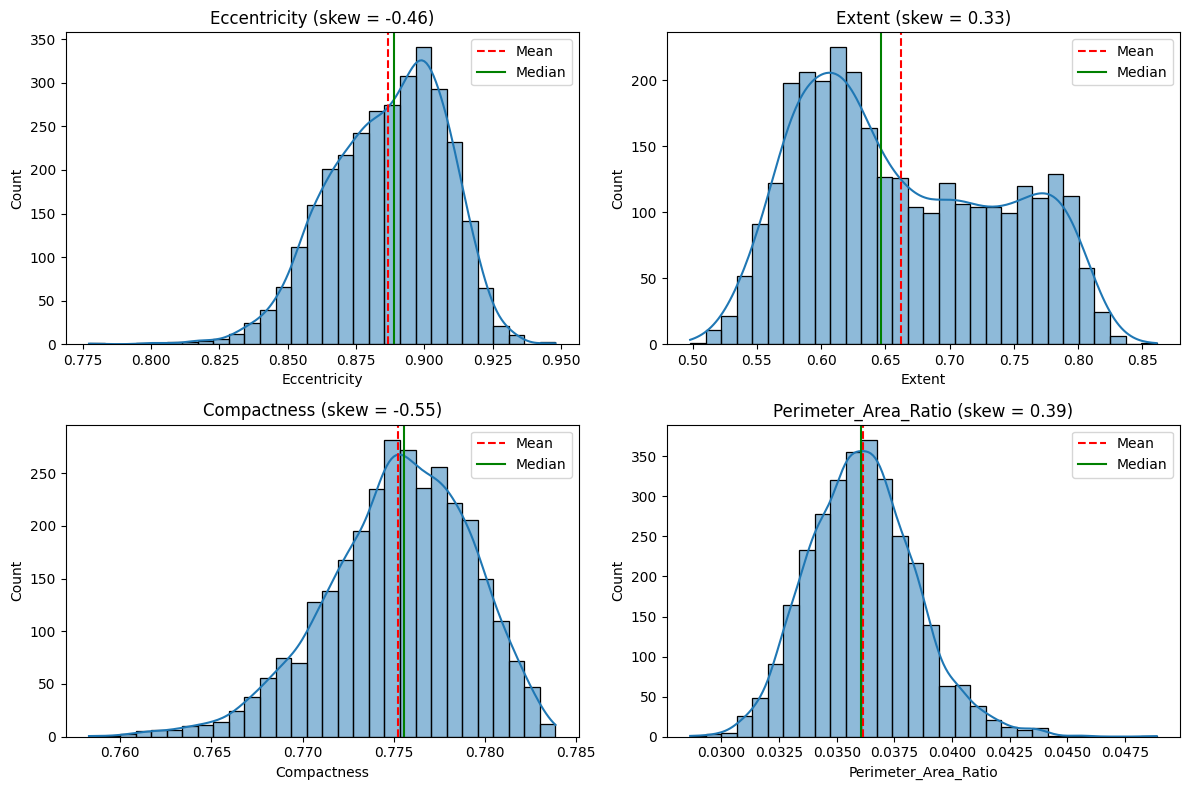

In [107]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

for i, col in enumerate(X_train.columns):
    sns.histplot(X_train[col], kde=True, bins=30, ax=axes[i])
    axes[i].axvline(X_train[col].mean(), color='red', linestyle='--', label='Mean')
    axes[i].axvline(X_train[col].median(), color='green', linestyle='-', label='Median')
    axes[i].set_title(f"{col} (skew = {X_train[col].skew():.2f})")
    axes[i].legend()

plt.tight_layout()
plt.show()

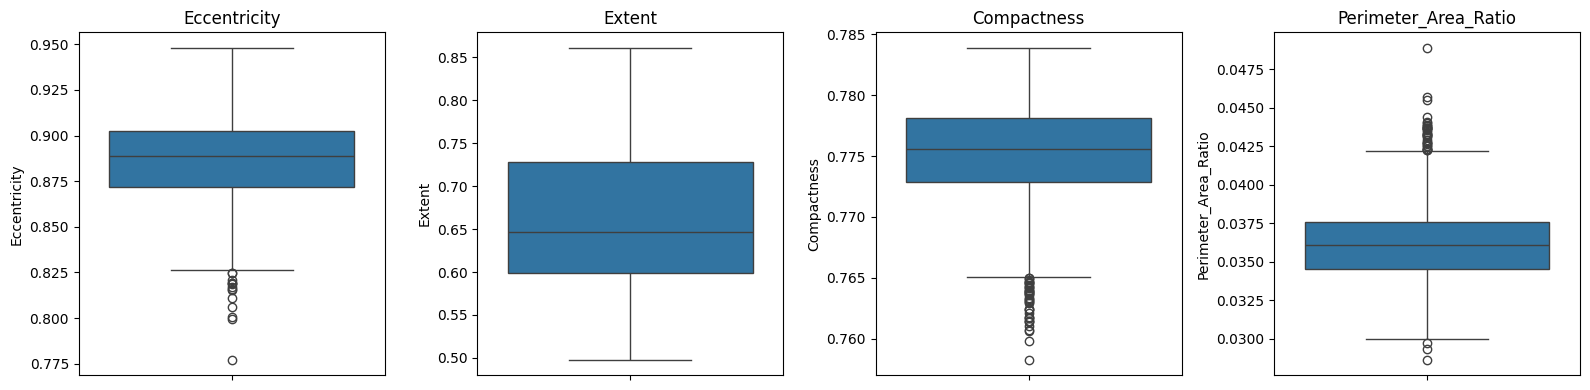

In [108]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for i, col in enumerate(X_train.columns):
    sns.boxplot(y=X_train[col], ax=axes[i])
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

##Final Observation before scaling:

* Eccentricity, Compactness, Perimeter_Area_Raio contains heavy outliers

* Compactness has a moderate Symmetricity

* Extent is normal



##Scaling decision
* Apply robust scaling for all features.
* To deal with the Assymmetry, we use Box-Cox for Compactness since the feature got positive values only.


##For Logistic Regression: Scaling

###Applying Robust scaling for all the features

In [109]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler, PowerTransformer

robust_cols  = ['Eccentricity', 'Extent', 'Perimeter_Area_Ratio']
boxcox_cols  = ['Compactness']

#Applying Box-Cox + RobustScaler
boxcox_robust = Pipeline([
    ('boxcox', PowerTransformer(method='box-cox', standardize=False)),
    ('robust', RobustScaler())
])

preprocessor_s2 = ColumnTransformer(
    transformers=[
        ('robust', RobustScaler(), robust_cols),
        ('boxcox_robust', boxcox_robust, boxcox_cols)
    ],
    remainder='drop'
)

In [110]:
X_train_s2 = preprocessor_s2.fit_transform(X_train)
X_test_s2  = preprocessor_s2.transform(X_test)

s2_cols = robust_cols + boxcox_cols
X_train_s2 = pd.DataFrame(X_train_s2, columns=s2_cols, index=X_train.index)
X_test_s2  = pd.DataFrame(X_test_s2,  columns=s2_cols, index=X_test.index)

lam = preprocessor_s2.named_transformers_['boxcox_robust'].named_steps['boxcox'].lambdas_
print("Compactness Box-Cox lambda:", lam)

print("\nCompactness skew before:", round(X_train['Compactness'].skew(), 4))
print("Compactness skew after :", round(X_train_s2['Compactness'].skew(), 4))

X_train_s2.describe().T

Compactness Box-Cox lambda: [38.32122052]

Compactness skew before: -0.5481
Compactness skew after : -0.0193


,count,mean,std,min,25%,50%,75%,max
Eccentricity,3048.0000,-0.0731,0.6821,-3.6226,-0.5563,0.0000,0.4437,1.9212
Extent,3048.0000,0.1217,0.5982,-1.1506,-0.3703,0.0000,0.6297,1.6590
Perimeter_Area_Ratio,3048.0000,0.0247,0.7535,-2.4098,-0.5069,-0.0000,0.4931,4.1666
Compactness,3048.0000,0.0142,0.7267,-2.2396,-0.4828,0.0000,0.5172,1.9624


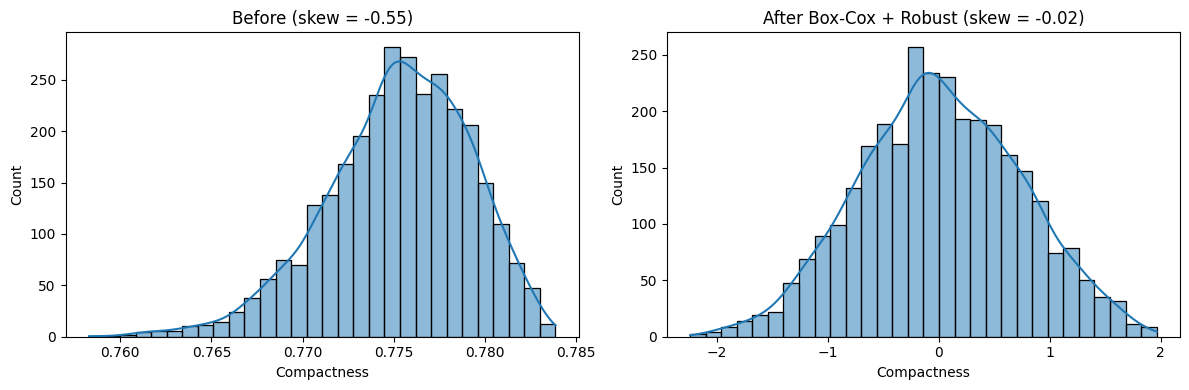

In [111]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(X_train['Compactness'], kde=True, bins=30, ax=axes[0])
axes[0].set_title(f"Before (skew = {X_train['Compactness'].skew():.2f})")

sns.histplot(X_train_s2['Compactness'], kde=True, bins=30, ax=axes[1])
axes[1].set_title(f"After Box-Cox + Robust (skew = {X_train_s2['Compactness'].skew():.2f})")

plt.tight_layout()
plt.show()

###Sanity Check

Checking Nulls

In [112]:
print("X_train_s2 shape:", X_train_s2.shape, "| y_train:", y_train.shape)
print("X_test_s2  shape:", X_test_s2.shape,  "| y_test :", y_test.shape)

print("\nIndex aligned with y?:", len(X_train_s2) == len(y_train))
print("Missing values (train):\n", X_train_s2.isnull().sum())
print("Missing values (test) :", X_test_s2.isnull().sum().sum())
print("Inf values (train/test):",
      np.isinf(X_train_s2).sum().sum(), "/", np.isinf(X_test_s2).sum().sum())
print("\nDtypes:\n", X_train_s2.dtypes)

X_train_s2 shape: (3048, 4) | y_train: (3048,)
X_test_s2  shape: (762, 4) | y_test : (762,)

Index aligned with y?: True
Missing values (train):
 Eccentricity            0
Extent                  0
Perimeter_Area_Ratio    0
Compactness             0
dtype: int64
Missing values (test) : 0
Inf values (train/test): 0 / 0

Dtypes:
 Eccentricity            float64
Extent                  float64
Perimeter_Area_Ratio    float64
Compactness             float64
dtype: object


Checking Whether the median=0, IQR=1 (Whether the scaler has fitted succesfully)

In [113]:
scale_check = pd.DataFrame({
    'Median': X_train_s2.median(),
    'Q1': X_train_s2.quantile(0.25),
    'Q3': X_train_s2.quantile(0.75),
    'IQR': X_train_s2.quantile(0.75) - X_train_s2.quantile(0.25),
    'Min': X_train_s2.min(),
    'Max': X_train_s2.max()
})
scale_check

,Median,Q1,Q3,IQR,Min,Max
Eccentricity,0.0000,-0.5563,0.4437,1.0000,-3.6226,1.9212
Extent,0.0000,-0.3703,0.6297,1.0000,-1.1506,1.6590
Perimeter_Area_Ratio,-0.0000,-0.5069,0.4931,1.0000,-2.4098,4.1666
Compactness,0.0000,-0.4828,0.5172,1.0000,-2.2396,1.9624


Checking whether the compactness skew has reduced

In [114]:
compare = pd.DataFrame({
    'Skew_Before': X_train.skew(),
    'Skew_After':  X_train_s2.skew(),
    'Kurt_After':  X_train_s2.kurt()
})
compare['Skew_Level_After'] = compare['Skew_After'].apply(skew_level)
display(compare)

display(iqr_outlier_summary(X_train_s2)[['Total_Outliers', 'Outlier_%']])

,Skew_Before,Skew_After,Kurt_After,Skew_Level_After
Compactness,-0.5481,-0.0193,-0.3039,Symmetric
Eccentricity,-0.4552,-0.4552,0.0897,Symmetric
Extent,0.3264,0.3264,-1.0573,Symmetric
Perimeter_Area_Ratio,0.3852,0.3852,0.6008,Symmetric


,Total_Outliers,Outlier_%
Feature,,
Eccentricity,14,0.4593
Extent,0,0.0000
Perimeter_Area_Ratio,37,1.2139
Compactness,5,0.1640


Histograms and boxplots

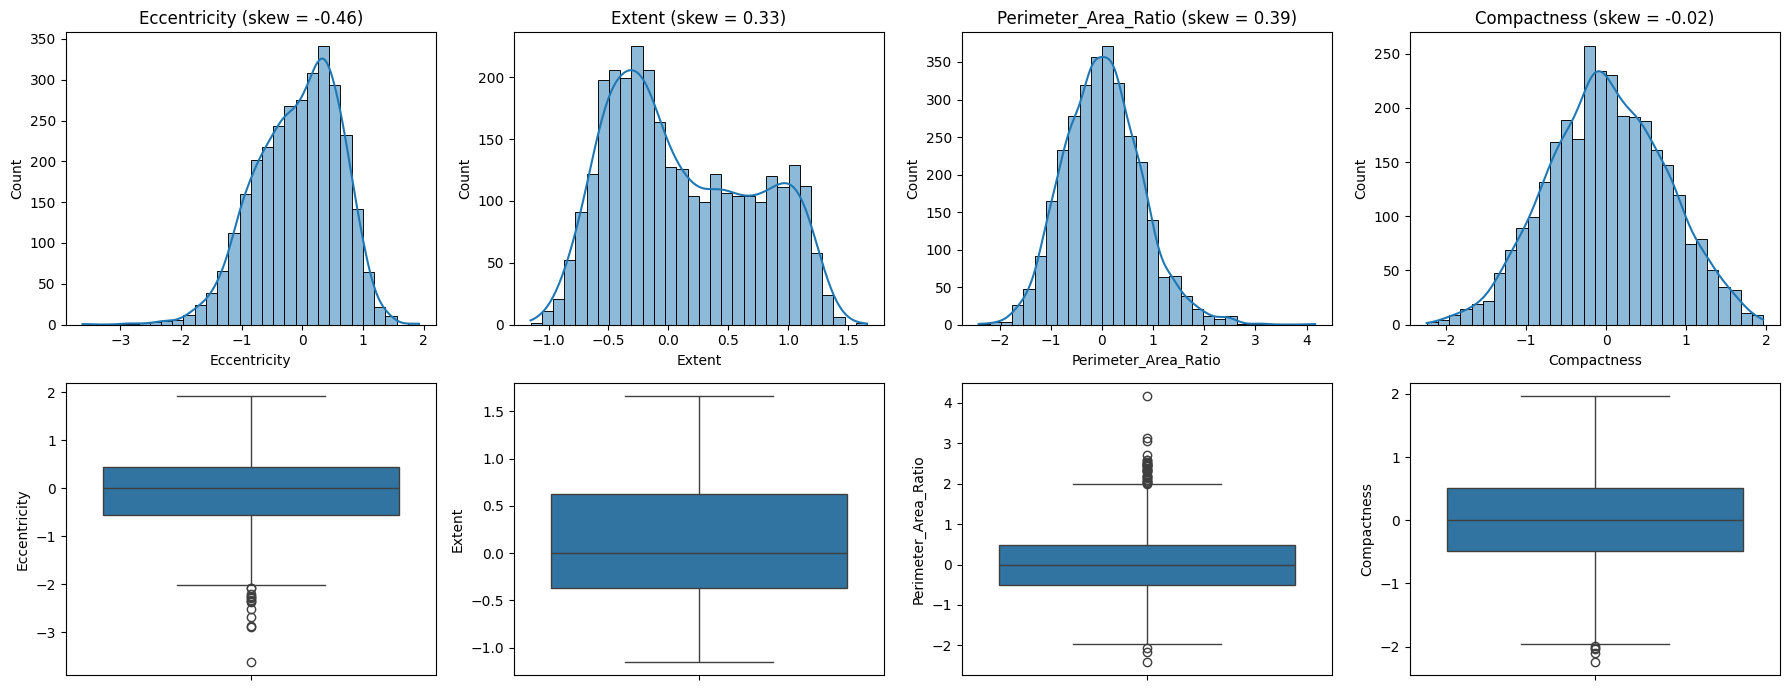

In [115]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for i, col in enumerate(X_train_s2.columns):
    sns.histplot(X_train_s2[col], kde=True, bins=30, ax=axes[0, i])
    axes[0, i].set_title(f"{col} (skew = {X_train_s2[col].skew():.2f})")
    sns.boxplot(y=X_train_s2[col], ax=axes[1, i])
plt.tight_layout()
plt.show()

Checking the class balance

In [116]:
print("Train class proportions:", dict(zip(le.classes_, (np.bincount(y_train)/len(y_train)).round(3))))
print("Test class proportions :", dict(zip(le.classes_, (np.bincount(y_test)/len(y_test)).round(3))))

shift = pd.DataFrame({
    'Train_Mean': X_train_s2.mean(),
    'Test_Mean':  X_test_s2.mean(),
    'Train_Std':  X_train_s2.std(),
    'Test_Std':   X_test_s2.std()
})
shift

Train class proportions: {'Cammeo': np.float64(0.428), 'Osmancik': np.float64(0.572)}
Test class proportions : {'Cammeo': np.float64(0.428), 'Osmancik': np.float64(0.572)}


,Train_Mean,Test_Mean,Train_Std,Test_Std
Eccentricity,-0.0731,-0.0248,0.6821,0.6489
Extent,0.1217,0.1020,0.5982,0.5965
Perimeter_Area_Ratio,0.0247,0.0620,0.7535,0.7771
Compactness,0.0142,0.0330,0.7267,0.7330


##Validation setup

In [117]:
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.linear_model import LogisticRegression

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_summary = {}

In [118]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline

def make_pipe(model):
    """Preprocessing is re-fitted inside every CV fold."""
    return Pipeline([("preprocess", clone(preprocessor_s2)), ("model", model)])

def clean_params(grid):
    """best_params_ without the 'model__' prefix (for rebuilding plain estimators)."""
    return {k.replace('model__', ''): v for k, v in grid.best_params_.items()}

In [119]:
param_grid_lr = {'model__C': [0.01, 0.1, 1, 10, 100]}

grid_lr = GridSearchCV(
    make_pipe(LogisticRegression(max_iter=1000, random_state=42)),
    param_grid_lr, cv=cv, scoring='accuracy', n_jobs=-1
)
grid_lr.fit(X_train, y_train)

print("Best params:", grid_lr.best_params_)
print("CV accuracy:", round(grid_lr.best_score_, 4))

idx = grid_lr.best_index_
cv_summary['Logistic Regression'] = (grid_lr.best_score_,
                                     grid_lr.cv_results_['std_test_score'][idx])

Best params: {'model__C': 10}
CV accuracy: 0.9272


In [120]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score

dummy_rows = {}
for strategy in ['most_frequent', 'stratified']:
    dummy = DummyClassifier(strategy=strategy, random_state=42)
    dummy.fit(X_train, y_train)
    y_pred_dummy = dummy.predict(X_test)
    dummy_rows[f'Dummy ({strategy})'] = {
        'Test Accuracy':     accuracy_score(y_test, y_pred_dummy),
        'Balanced Accuracy': balanced_accuracy_score(y_test, y_pred_dummy),
        'Macro-F1':          f1_score(y_test, y_pred_dummy, average='macro'),
    }

pd.DataFrame(dummy_rows).T.round(4)

,Test Accuracy,Balanced Accuracy,Macro-F1
Dummy (most_frequent),0.5722,0.5000,0.3639
Dummy (stratified),0.4961,0.4850,0.4849


In [121]:
dummy_cv = cross_val_score(
    DummyClassifier(strategy='most_frequent'),
    X_train, y_train, cv=cv, scoring='accuracy'
)
cv_summary['Dummy (majority)'] = (dummy_cv.mean(), dummy_cv.std())

print("Dummy CV accuracy:", round(dummy_cv.mean(), 4), "+/-", round(dummy_cv.std(), 4))

Dummy CV accuracy: 0.5722 +/- 0.0005


###Logistic Regression

Accuracy : 0.9081
Precision: 0.9103
Recall   : 0.9312
F1       : 0.9206
ROC-AUC  : 0.9706

               precision    recall  f1-score   support

      Cammeo       0.91      0.88      0.89       326
    Osmancik       0.91      0.93      0.92       436

    accuracy                           0.91       762
   macro avg       0.91      0.90      0.91       762
weighted avg       0.91      0.91      0.91       762

Train accuracy: 0.9272
Test accuracy : 0.9081

Coefficients:
 Eccentricity           -4.7917
Perimeter_Area_Ratio    4.3585
Compactness             0.7517
Extent                  0.2028
dtype: float64


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


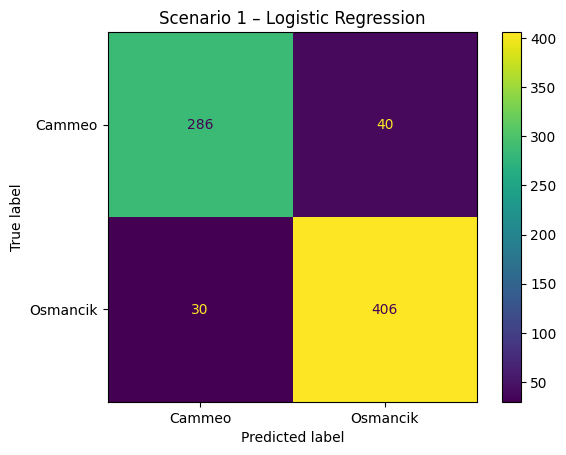

In [122]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             ConfusionMatrixDisplay)

lr_best = grid_lr.best_estimator_
lr_s2   = lr_best.named_steps['model']
assert (lr_best.predict(X_test) == lr_s2.predict(X_test_s2)).all()

y_pred = lr_s2.predict(X_test_s2)
y_prob = lr_s2.predict_proba(X_test_s2)[:, 1]

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1       :", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 4))
print("\n", classification_report(y_test, y_pred, target_names=le.classes_))

# Train vs Test accuracy (overfitting check)
print("Train accuracy:", round(lr_s2.score(X_train_s2, y_train), 4))
print("Test accuracy :", round(lr_s2.score(X_test_s2, y_test), 4))

# Coefficients
coef = pd.Series(lr_s2.coef_[0], index=X_train_s2.columns).sort_values(key=abs, ascending=False)
print("\nCoefficients:\n", coef.round(4))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=le.classes_)
plt.title("Scenario 1 – Logistic Regression")
plt.show()

Sigmoid Chart

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


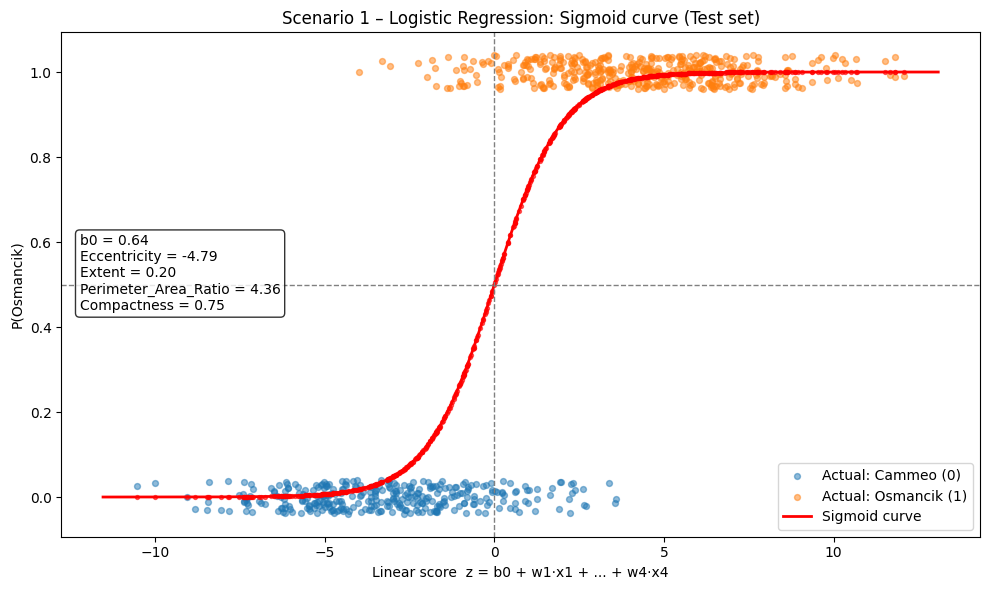

In [123]:
z_test = lr_s2.decision_function(X_test_s2)
p_test = lr_s2.predict_proba(X_test_s2)[:, 1]

z_line = np.linspace(z_test.min() - 1, z_test.max() + 1, 300)
p_line = 1 / (1 + np.exp(-z_line))

rng = np.random.RandomState(42)
y_jit = y_test + rng.uniform(-0.04, 0.04, size=len(y_test))

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(z_test[y_test == 0], y_jit[y_test == 0], color='tab:blue',   alpha=0.5, s=18, label='Actual: Cammeo (0)')
ax.scatter(z_test[y_test == 1], y_jit[y_test == 1], color='tab:orange', alpha=0.5, s=18, label='Actual: Osmancik (1)')

ax.plot(z_line, p_line, color='red', linewidth=2, label='Sigmoid curve')
ax.scatter(z_test, p_test, color='red', s=8, alpha=0.6)

ax.axhline(0.5, color='gray', linestyle='--', linewidth=1)
ax.axvline(0, color='gray', linestyle='--', linewidth=1)

ax.text(0.02, 0.60,
        f"b0 = {lr_s2.intercept_[0]:.2f}\n" +
        "\n".join([f"{c} = {w:.2f}" for c, w in zip(X_train_s2.columns, lr_s2.coef_[0])]),
        transform=ax.transAxes, fontsize=10, va='top',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax.set_xlabel("Linear score  z = b0 + w1·x1 + ... + w4·x4")
ax.set_ylabel("P(Osmancik)")
ax.set_title("Scenario 1 – Logistic Regression: Sigmoid curve (Test set)")
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

For Random Forest

###Validation


In [124]:
from sklearn.ensemble import RandomForestClassifier

param_grid_rf = {
    'model__max_depth': [None, 5, 10, 15],
    'model__min_samples_leaf': [1, 3, 5, 10],
}

grid_rf = GridSearchCV(
    make_pipe(RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)),
    param_grid_rf, cv=cv, scoring='accuracy'
)
grid_rf.fit(X_train, y_train)

print("Best params:", grid_rf.best_params_)
print("CV accuracy:", round(grid_rf.best_score_, 4))

idx = grid_rf.best_index_
cv_summary['Random Forest'] = (grid_rf.best_score_,
                               grid_rf.cv_results_['std_test_score'][idx])

Best params: {'model__max_depth': 10, 'model__min_samples_leaf': 5}
CV accuracy: 0.9275


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


Accuracy : 0.9055
Precision: 0.9044
Recall   : 0.9335
F1       : 0.9187
ROC-AUC  : 0.9669

               precision    recall  f1-score   support

      Cammeo       0.91      0.87      0.89       326
    Osmancik       0.90      0.93      0.92       436

    accuracy                           0.91       762
   macro avg       0.91      0.90      0.90       762
weighted avg       0.91      0.91      0.91       762

Train accuracy: 0.9577


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


Test accuracy : 0.9055


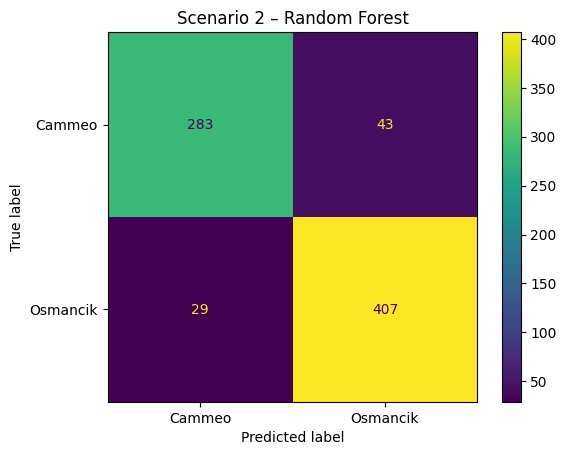

In [125]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             ConfusionMatrixDisplay)

rf_s2 = grid_rf.best_estimator_.named_steps['model']
assert (grid_rf.best_estimator_.predict(X_test) == rf_s2.predict(X_test_s2)).all()

y_pred_rf = rf_s2.predict(X_test_s2)
y_prob_rf = rf_s2.predict_proba(X_test_s2)[:, 1]

print("Accuracy :", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf), 4))
print("Recall   :", round(recall_score(y_test, y_pred_rf), 4))
print("F1       :", round(f1_score(y_test, y_pred_rf), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob_rf), 4))
print("\n", classification_report(y_test, y_pred_rf, target_names=le.classes_))

print("Train accuracy:", round(rf_s2.score(X_train_s2, y_train), 4))
print("Test accuracy :", round(rf_s2.score(X_test_s2, y_test), 4))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf, display_labels=le.classes_)
plt.title("Scenario 2 – Random Forest")
plt.show()

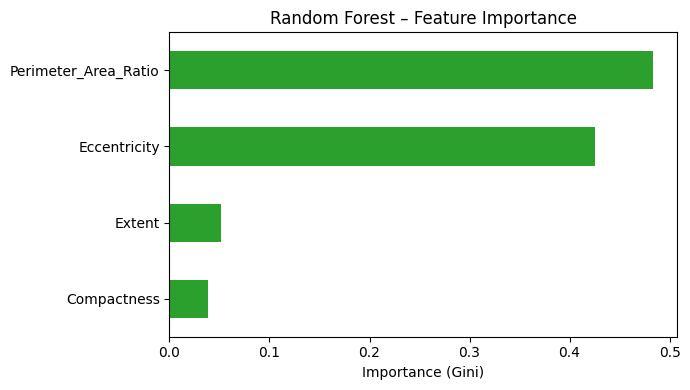

,0
Perimeter_Area_Ratio,0.4834
Eccentricity,0.4259
Extent,0.0520
Compactness,0.0387


In [126]:
imp = pd.Series(rf_s2.feature_importances_, index=X_train_s2.columns).sort_values()

plt.figure(figsize=(7, 4))
imp.plot(kind='barh', color='tab:green')
plt.xlabel("Importance (Gini)")
plt.title("Random Forest – Feature Importance")
plt.tight_layout()
plt.show()

imp.sort_values(ascending=False).round(4)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


,Logistic Regression,Random Forest
Accuracy,0.9081,0.9055
Precision,0.9103,0.9044
Recall,0.9312,0.9335
F1,0.9206,0.9187
ROC-AUC,0.9706,0.9669
Train Accuracy,0.9272,0.9577


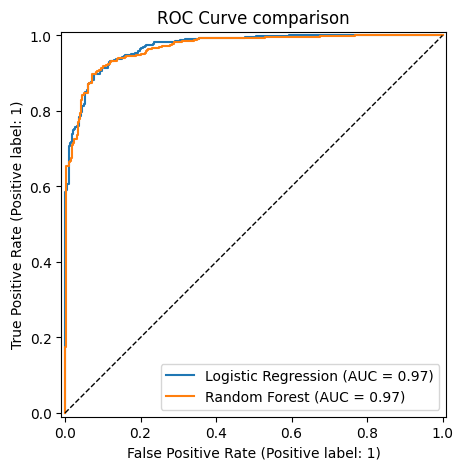

In [127]:
results = pd.DataFrame({
    'Logistic Regression': [
        accuracy_score(y_test, y_pred), precision_score(y_test, y_pred),
        recall_score(y_test, y_pred), f1_score(y_test, y_pred),
        roc_auc_score(y_test, y_prob), lr_s2.score(X_train_s2, y_train)],
    'Random Forest': [
        accuracy_score(y_test, y_pred_rf), precision_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_rf), f1_score(y_test, y_pred_rf),
        roc_auc_score(y_test, y_prob_rf), rf_s2.score(X_train_s2, y_train)]
}, index=['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'Train Accuracy']).round(4)
display(results)

# ROC curves
from sklearn.metrics import RocCurveDisplay
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_test, y_prob,    name='Logistic Regression', ax=ax)
RocCurveDisplay.from_predictions(y_test, y_prob_rf, name='Random Forest', ax=ax)
ax.plot([0, 1], [0, 1], 'k--', linewidth=1)
ax.set_title("ROC Curve comparison")
plt.show()

##K-Nearest Neighbours

In [128]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             ConfusionMatrixDisplay)

knn_base = KNeighborsClassifier(n_neighbors=5)
knn_base.fit(X_train_s2, y_train)

print("Baseline k=5 | Train acc:", round(knn_base.score(X_train_s2, y_train), 4),
      "| Test acc:", round(knn_base.score(X_test_s2, y_test), 4))

Baseline k=5 | Train acc: 0.9373 | Test acc: 0.9016


In [129]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
k_values = range(1, 32, 2)

knn_fold_scores = {}
for k in k_values:
    pipe = make_pipe(KNeighborsClassifier(n_neighbors=k))
    knn_fold_scores[k] = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='accuracy')

cv_scores = [knn_fold_scores[k].mean() for k in k_values]
cv_stds   = [knn_fold_scores[k].std()  for k in k_values]
best_k    = list(k_values)[int(np.argmax(cv_scores))]
print("Best k:", best_k, "| CV accuracy:", round(max(cv_scores), 4),
      "| CV std:", round(cv_stds[list(k_values).index(best_k)], 4))

Best k: 29 | CV accuracy: 0.9236 | CV std: 0.0074


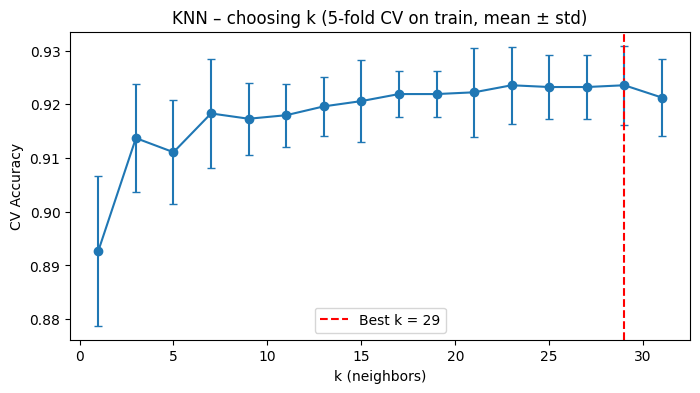

In [130]:
plt.figure(figsize=(8, 4))
plt.errorbar(list(k_values), cv_scores, yerr=cv_stds, marker='o', capsize=3)
plt.axvline(best_k, color='red', linestyle='--', label=f'Best k = {best_k}')
plt.xlabel("k (neighbors)"); plt.ylabel("CV Accuracy")
plt.title("KNN – choosing k (5-fold CV on train, mean ± std)")
plt.legend(); plt.show()

Accuracy : 0.899
Precision: 0.9016
Recall   : 0.9243
F1       : 0.9128
ROC-AUC  : 0.9658

               precision    recall  f1-score   support

      Cammeo       0.90      0.87      0.88       326
    Osmancik       0.90      0.92      0.91       436

    accuracy                           0.90       762
   macro avg       0.90      0.89      0.90       762
weighted avg       0.90      0.90      0.90       762

Train accuracy: 0.9268
Test accuracy : 0.899


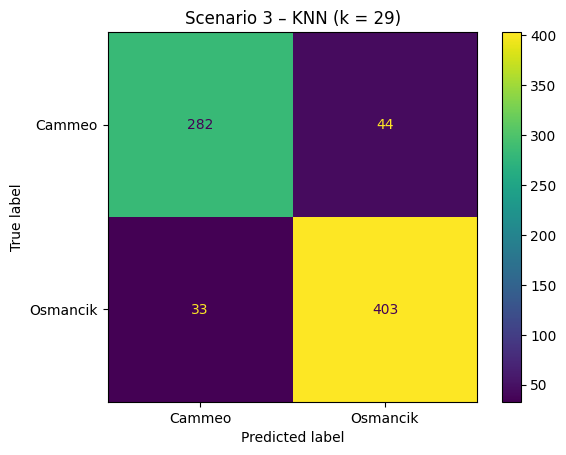

In [131]:
knn_s3 = KNeighborsClassifier(n_neighbors=best_k)
knn_s3.fit(X_train_s2, y_train)

y_pred_knn = knn_s3.predict(X_test_s2)
y_prob_knn = knn_s3.predict_proba(X_test_s2)[:, 1]

print("Accuracy :", round(accuracy_score(y_test, y_pred_knn), 4))
print("Precision:", round(precision_score(y_test, y_pred_knn), 4))
print("Recall   :", round(recall_score(y_test, y_pred_knn), 4))
print("F1       :", round(f1_score(y_test, y_pred_knn), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob_knn), 4))
print("\n", classification_report(y_test, y_pred_knn, target_names=le.classes_))

print("Train accuracy:", round(knn_s3.score(X_train_s2, y_train), 4))
print("Test accuracy :", round(knn_s3.score(X_test_s2, y_test), 4))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_knn, display_labels=le.classes_)
plt.title(f"Scenario 3 – KNN (k = {best_k})")
plt.show()

In [132]:
from sklearn.neighbors import KNeighborsClassifier

f1, f2 = 'Eccentricity', 'Perimeter_Area_Ratio'
X2_train = X_train_s2[[f1, f2]]

knn_2d = KNeighborsClassifier(n_neighbors=best_k)
knn_2d.fit(X2_train, y_train)

xx, yy = np.meshgrid(
    np.linspace(X2_train[f1].min() - 0.5, X2_train[f1].max() + 0.5, 300),
    np.linspace(X2_train[f2].min() - 0.5, X2_train[f2].max() + 0.5, 300)
)
grid_2d = pd.DataFrame({f1: xx.ravel(), f2: yy.ravel()})
zz = knn_2d.predict(grid_2d).reshape(xx.shape)

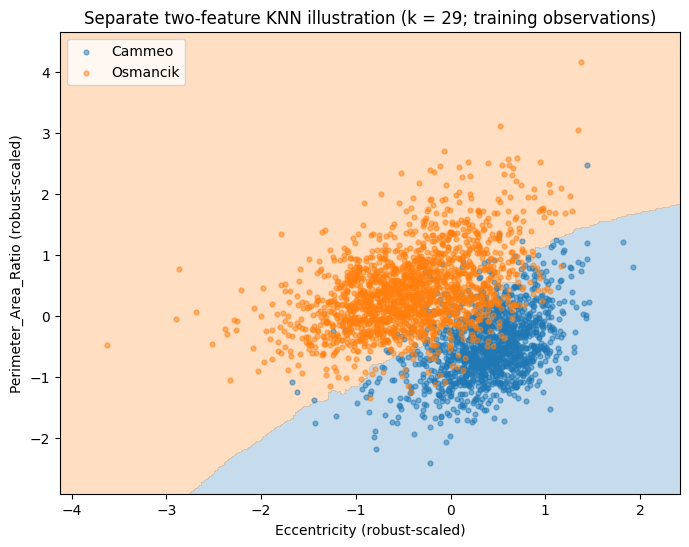

In [133]:
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], alpha=0.25,
             colors=['tab:blue', 'tab:orange'])

for cls_id, cls_name in enumerate(le.classes_):
    mask = (y_train == cls_id)
    plt.scatter(X2_train.loc[mask, f1], X2_train.loc[mask, f2],
                s=12, alpha=0.5, label=cls_name)

plt.xlabel(f"{f1} (robust-scaled)"); plt.ylabel(f"{f2} (robust-scaled)")
plt.title(f"Separate two-feature KNN illustration (k = {best_k}; training observations)")
plt.legend()
plt.show()

##Support Vector Machines

###RBF SVM tuning

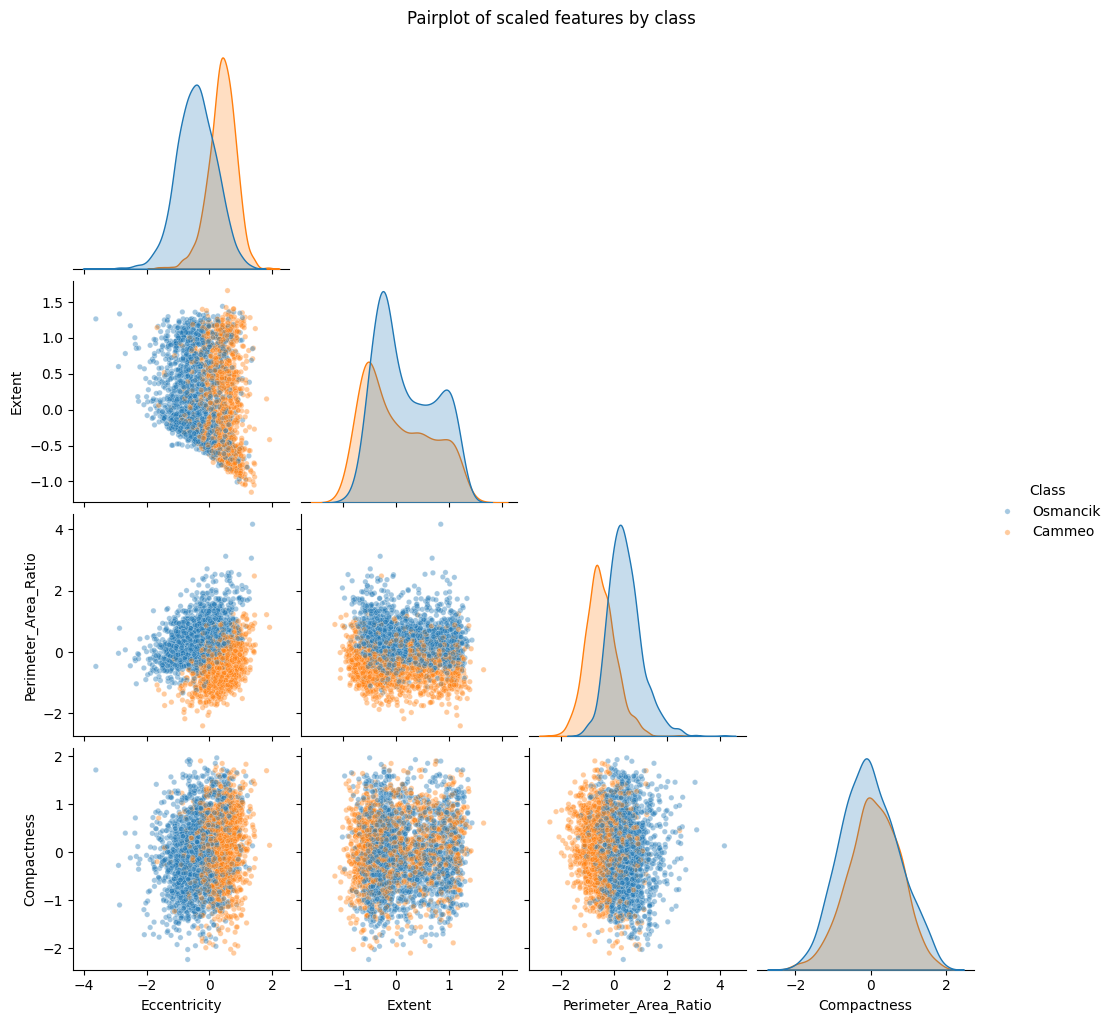

In [134]:
eda_df = X_train_s2.copy()
eda_df['Class'] = le.inverse_transform(y_train)

sns.pairplot(eda_df, hue='Class', corner=True,
             plot_kws={'alpha': 0.4, 's': 15}, diag_kind='kde')
plt.suptitle("Pairplot of scaled features by class", y=1.02)
plt.show()

Explained variance ratio: [0.34  0.272] | Total: 0.612


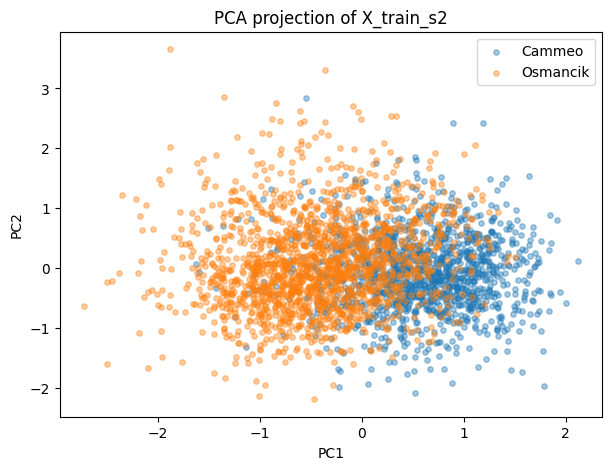

In [135]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
Z = pca.fit_transform(X_train_s2)
print("Explained variance ratio:", pca.explained_variance_ratio_.round(3),
      "| Total:", pca.explained_variance_ratio_.sum().round(3))

plt.figure(figsize=(7, 5))
for cls_id, cls_name in enumerate(le.classes_):
    plt.scatter(Z[y_train == cls_id, 0], Z[y_train == cls_id, 1],
                alpha=0.4, s=15, label=cls_name)
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("PCA projection of X_train_s2")
plt.legend()
plt.show()

In [136]:
from sklearn.svm import SVC

param_grid_svm = {
    'model__C': [0.1, 1, 10, 100],
    'model__gamma': ['scale', 0.01, 0.1, 1],
}

grid_svm = GridSearchCV(
    make_pipe(SVC(kernel='rbf', random_state=42)),
    param_grid_svm, cv=cv, scoring='accuracy', n_jobs=-1
)
grid_svm.fit(X_train, y_train)

print("Best params:", grid_svm.best_params_)
print("CV accuracy:", round(grid_svm.best_score_, 4))

idx = grid_svm.best_index_
cv_summary['SVM'] = (grid_svm.best_score_, grid_svm.cv_results_['std_test_score'][idx])

Best params: {'model__C': 1, 'model__gamma': 0.1}
CV accuracy: 0.9295


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(


Accuracy : 0.9081
Precision: 0.9122
Recall   : 0.9289
F1       : 0.9205
ROC-AUC  : 0.9702

               precision    recall  f1-score   support

      Cammeo       0.90      0.88      0.89       326
    Osmancik       0.91      0.93      0.92       436

    accuracy                           0.91       762
   macro avg       0.91      0.90      0.91       762
weighted avg       0.91      0.91      0.91       762

Train accuracy: 0.9301
Test accuracy : 0.9081


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(


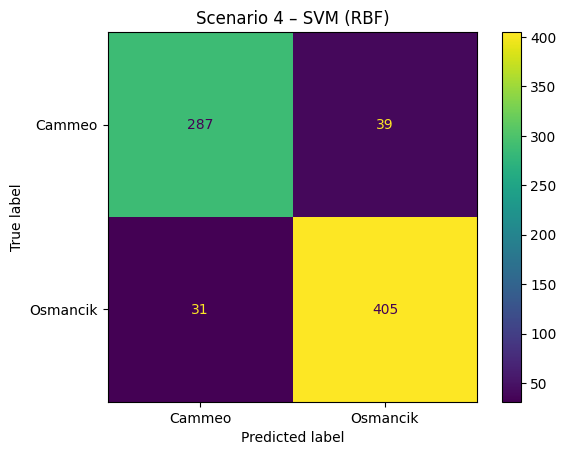

In [137]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             ConfusionMatrixDisplay)

svm_s2 = grid_svm.best_estimator_.named_steps['model']
assert (grid_svm.best_estimator_.predict(X_test) == svm_s2.predict(X_test_s2)).all()

y_pred_svm = svm_s2.predict(X_test_s2)
y_score_svm = svm_s2.decision_function(X_test_s2)

print("Accuracy :", round(accuracy_score(y_test, y_pred_svm), 4))
print("Precision:", round(precision_score(y_test, y_pred_svm), 4))
print("Recall   :", round(recall_score(y_test, y_pred_svm), 4))
print("F1       :", round(f1_score(y_test, y_pred_svm), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_score_svm), 4))
print("\n", classification_report(y_test, y_pred_svm, target_names=le.classes_))

print("Train accuracy:", round(svm_s2.score(X_train_s2, y_train), 4))
print("Test accuracy :", round(svm_s2.score(X_test_s2, y_test), 4))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_svm, display_labels=le.classes_)
plt.title("Scenario 4 – SVM (RBF)")
plt.show()

In [138]:
n_sv = svm_s2.n_support_
print("Support vectors per class:", dict(zip(le.classes_, n_sv)))
print("Total SV:", n_sv.sum(), "| % of train:", round(100 * n_sv.sum() / len(X_train_s2), 2), "%")

Support vectors per class: {'Cammeo': np.int32(329), 'Osmancik': np.int32(330)}
Total SV: 659 | % of train: 21.62 %


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(


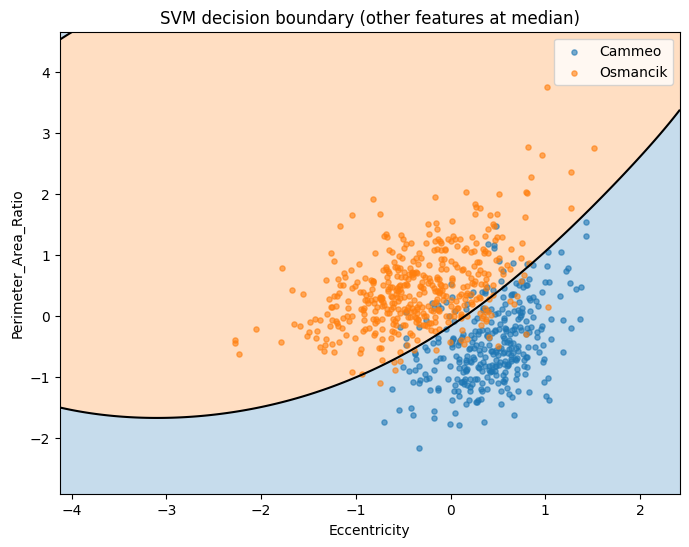

In [139]:
f1, f2 = 'Eccentricity', 'Perimeter_Area_Ratio'
xx, yy = np.meshgrid(np.linspace(X_train_s2[f1].min()-0.5, X_train_s2[f1].max()+0.5, 300),
                     np.linspace(X_train_s2[f2].min()-0.5, X_train_s2[f2].max()+0.5, 300))

grid_df = pd.DataFrame({c: np.full(xx.size, X_train_s2[c].median()) for c in X_train_s2.columns})
grid_df[f1], grid_df[f2] = xx.ravel(), yy.ravel()
zz = svm_s2.decision_function(grid_df).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, zz, levels=[-100, 0, 100], alpha=0.25, colors=['tab:blue', 'tab:orange'])
plt.contour(xx, yy, zz, levels=[0], colors='k', linewidths=1.5)
for cls_id, cls_name in enumerate(le.classes_):
    m = y_test == cls_id
    plt.scatter(X_test_s2.loc[m, f1] if hasattr(X_test_s2, 'loc') else X_test_s2[m, 0],
                X_test_s2.loc[m, f2] if hasattr(X_test_s2, 'loc') else X_test_s2[m, 1],
                s=14, alpha=0.6, label=cls_name)
plt.xlabel(f1); plt.ylabel(f2)
plt.title("SVM decision boundary (other features at median)")
plt.legend()
plt.show()

##Model Conparison

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(


,Logistic Regression,Random Forest,KNN (k=29),SVM (RBF)
Accuracy,0.9081,0.9055,0.8990,0.9081
Precision,0.9103,0.9044,0.9016,0.9122
Recall,0.9312,0.9335,0.9243,0.9289
F1,0.9206,0.9187,0.9128,0.9205
ROC-AUC,0.9706,0.9669,0.9658,0.9702
Train Accuracy,0.9272,0.9577,0.9268,0.9301


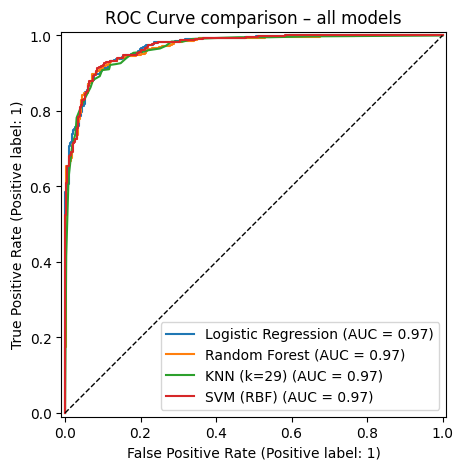

In [140]:
from sklearn.metrics import RocCurveDisplay

models = {
    'Logistic Regression': (y_pred,     y_prob,      lr_s2),
    'Random Forest':       (y_pred_rf,  y_prob_rf,   rf_s2),
    f'KNN (k={best_k})':   (y_pred_knn, y_prob_knn,  knn_s3),
    'SVM (RBF)':           (y_pred_svm, y_score_svm, svm_s2),
}

rows = {}
for name, (yp, ysc, mdl) in models.items():
    rows[name] = [accuracy_score(y_test, yp), precision_score(y_test, yp),
                  recall_score(y_test, yp), f1_score(y_test, yp),
                  roc_auc_score(y_test, ysc), mdl.score(X_train_s2, y_train)]

results = pd.DataFrame(rows, index=['Accuracy','Precision','Recall','F1','ROC-AUC','Train Accuracy']).round(4)
display(results)

fig, ax = plt.subplots(figsize=(6, 5))
for name, (yp, ysc, mdl) in models.items():
    RocCurveDisplay.from_predictions(y_test, ysc, name=name, ax=ax)
ax.plot([0, 1], [0, 1], 'k--', linewidth=1)
ax.set_title("ROC Curve comparison – all models")
plt.show()

In [141]:
from sklearn.metrics import balanced_accuracy_score, f1_score, recall_score

def extra_metrics(yp):
    return [balanced_accuracy_score(y_test, yp),
            f1_score(y_test, yp, average='macro'),
            recall_score(y_test, yp, pos_label=0),
            recall_score(y_test, yp, pos_label=1)]

extra = {name: extra_metrics(yp) for name, (yp, ysc, mdl) in models.items()}
y_pred_majority = DummyClassifier(strategy='most_frequent').fit(X_train, y_train).predict(X_test)
extra['Dummy (majority)'] = extra_metrics(y_pred_majority)

pd.DataFrame(extra, index=['Balanced Acc', 'Macro-F1',
                           f'Recall {le.classes_[0]}', f'Recall {le.classes_[1]}']).T.round(4)

,Balanced Acc,Macro-F1,Recall Cammeo,Recall Osmancik
Logistic Regression,0.9042,0.9058,0.8773,0.9312
Random Forest,0.9008,0.9029,0.8681,0.9335
KNN (k=29),0.8947,0.8963,0.8650,0.9243
SVM (RBF),0.9046,0.9059,0.8804,0.9289
Dummy (majority),0.5000,0.3639,0.0000,1.0000


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature n

,Train Accuracy,Test Accuracy,Gap (Train - Test)
Logistic Regression,0.9272,0.9081,0.0190
Random Forest,0.9577,0.9055,0.0522
KNN (k=29),0.9268,0.8990,0.0279
SVM (RBF),0.9301,0.9081,0.0220


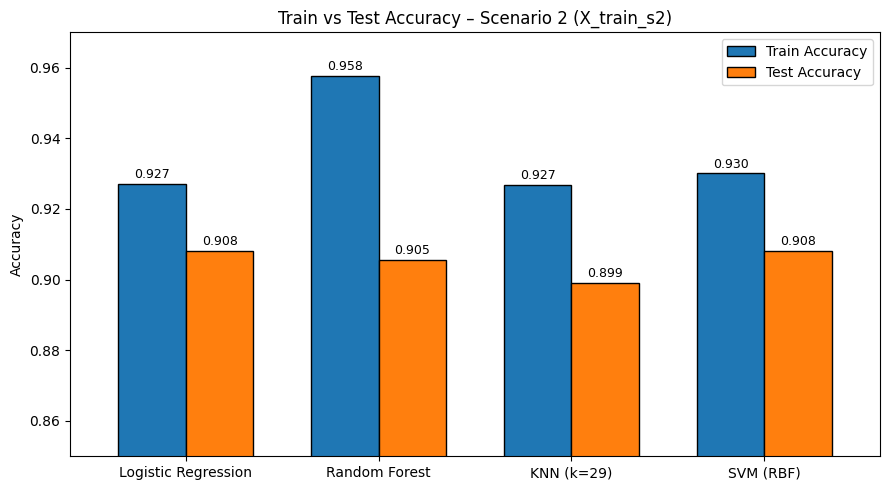

In [142]:
models_acc = {
    'Logistic Regression': lr_s2,
    'Random Forest':       rf_s2,
    f'KNN (k={best_k})':   knn_s3,
    'SVM (RBF)':           svm_s2,
}

acc_df = pd.DataFrame({
    'Train Accuracy': {n: m.score(X_train_s2, y_train) for n, m in models_acc.items()},
    'Test Accuracy':  {n: m.score(X_test_s2,  y_test)  for n, m in models_acc.items()},
})
acc_df['Gap (Train - Test)'] = acc_df['Train Accuracy'] - acc_df['Test Accuracy']
acc_df = acc_df.round(4)
display(acc_df)


ax = acc_df[['Train Accuracy', 'Test Accuracy']].plot(
    kind='bar', figsize=(9, 5), width=0.7, color=['tab:blue', 'tab:orange'], edgecolor='black')

for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=2, fontsize=9)

ax.set_ylim(0.85, 0.97)
ax.set_ylabel("Accuracy")
ax.set_title("Train vs Test Accuracy – Scenario 2 (X_train_s2)")
plt.xticks(rotation=0)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

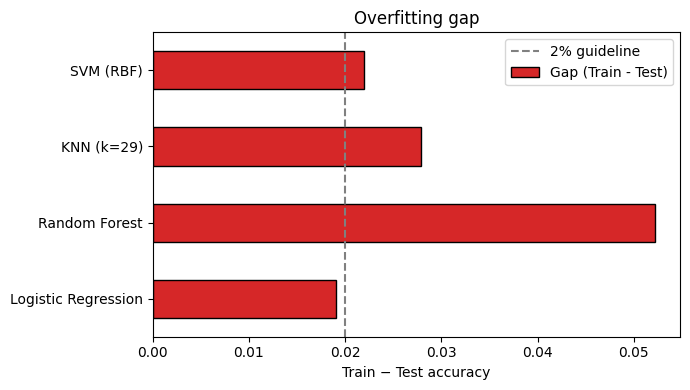

In [143]:
plt.figure(figsize=(7, 4))
acc_df['Gap (Train - Test)'].plot(kind='barh', color='tab:red', edgecolor='black')
plt.axvline(0.02, color='gray', linestyle='--', label='2% guideline')
plt.xlabel("Train − Test accuracy")
plt.title("Overfitting gap")
plt.legend()
plt.tight_layout()
plt.show()

Gap < 2%: Generalized

Gap 2–5%: Little bit overfitting.

Gap > 5%: Clear overfitting.

In [144]:
knn_idx = list(k_values).index(best_k)
cv_summary['KNN'] = (cv_scores[knn_idx], cv_stds[knn_idx])

pd.DataFrame(cv_summary, index=['CV mean acc', 'CV std']).T.round(4)

,CV mean acc,CV std
Logistic Regression,0.9272,0.0045
Dummy (majority),0.5722,0.0005
Random Forest,0.9275,0.0070
SVM,0.9295,0.0055
KNN,0.9236,0.0074


##Riginal measurements vs engineered features

In [145]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, PowerTransformer

orig_features = ['Area', 'Perimeter', 'Major_Axis_Length', 'Minor_Axis_Length',
                 'Eccentricity', 'Convex_Area', 'Extent']

# Raw measurements + the two engineered ratios, all on the SAME rows as the existing split
df_all = df.copy()
df_all['Perimeter_Area_Ratio'] = df_all['Perimeter'] / df_all['Area']
df_all['Compactness'] = df_all['Area'] / (df_all['Major_Axis_Length'] * df_all['Minor_Axis_Length'])

train_idx, test_idx = X_train.index, X_test.index

# Sanity check: the labels line up with the existing y_train / y_test
assert (le.transform(df_all.loc[train_idx, target_col]) == y_train).all()
assert (le.transform(df_all.loc[test_idx,  target_col]) == y_test).all()
print("Rows aligned with the existing split.")

Rows aligned with the existing split.


In [146]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

def vif_prune(frame, threshold=10):
    """Repeatedly drop the feature with the highest VIF until all VIF <= threshold."""
    cols = list(frame.columns)
    while len(cols) > 1:
        Xv = add_constant(frame[cols])
        vifs = pd.Series([variance_inflation_factor(Xv.values, i + 1) for i in range(len(cols))],
                         index=cols)
        if vifs.max() <= threshold:
            break
        cols.remove(vifs.idxmax())
    return cols, vifs

# TRAINING rows only, so the selection does not see the test set
vif_cols, vif_final = vif_prune(df_all.loc[train_idx, orig_features])
print("Original features kept after VIF pruning:", vif_cols)
vif_final.round(2)

Original features kept after VIF pruning: ['Minor_Axis_Length', 'Eccentricity', 'Extent']


,0
Minor_Axis_Length,1.0900
Eccentricity,1.1400
Extent,1.0400


In [147]:
def make_preprocessor(cols):
    """Same logic as preprocessor_s2: RobustScaler everywhere,
    Box-Cox + RobustScaler on Compactness (only if Compactness is in cols)."""
    plain = [c for c in cols if c != 'Compactness']
    transformers = []
    if plain:
        transformers.append(('robust', RobustScaler(), plain))
    if 'Compactness' in cols:
        transformers.append(('boxcox_robust',
                             Pipeline([('boxcox', PowerTransformer(method='box-cox', standardize=False)),
                                       ('robust', RobustScaler())]),
                             ['Compactness']))
    return ColumnTransformer(transformers, remainder='drop')

feature_sets = {
    'A: all 7 original':                      orig_features,
    'B: 6 originals behind the 4 engineered': ['Eccentricity', 'Extent', 'Area',
                                               'Major_Axis_Length', 'Minor_Axis_Length', 'Perimeter'],
    'C: VIF-pruned originals (train only)':   vif_cols,
    'D: 4 engineered (current)':              keep_cols,
}

for name, cols in feature_sets.items():
    print(f"{name:<42} {len(cols)} features")

A: all 7 original                          7 features
B: 6 originals behind the 4 engineered     6 features
C: VIF-pruned originals (train only)       3 features
D: 4 engineered (current)                  4 features


In [148]:
from sklearn.model_selection import cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score

# Hyper-parameters reused from the earlier tuning (see note below the table)
model_factories = {
    'Logistic Regression': lambda: LogisticRegression(max_iter=1000, random_state=42, **clean_params(grid_lr)),
    'Random Forest':       lambda: RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1, **clean_params(grid_rf)),
    f'KNN (k={best_k})':   lambda: KNeighborsClassifier(n_neighbors=best_k),
    'SVM (RBF)':           lambda: SVC(kernel='rbf', random_state=42, **clean_params(grid_svm)),
}

rows = []
for set_name, cols in feature_sets.items():
    Xtr, Xte = df_all.loc[train_idx, cols], df_all.loc[test_idx, cols]
    for model_name, make_model in model_factories.items():
        pipe = Pipeline([('prep', make_preprocessor(cols)), ('model', make_model())])

        cvr = cross_validate(pipe, Xtr, y_train, cv=cv,
                             scoring=['accuracy', 'f1_macro', 'balanced_accuracy'])
        pipe.fit(Xtr, y_train)
        yp = pipe.predict(Xte)

        rows.append({
            'Feature set': set_name, 'Model': model_name, 'n_features': len(cols),
            'CV Acc (mean)': cvr['test_accuracy'].mean(),
            'CV Acc (std)':  cvr['test_accuracy'].std(),
            'Test Acc':      accuracy_score(y_test, yp),
            'Test Balanced Acc': balanced_accuracy_score(y_test, yp),
            'Test Macro-F1': f1_score(y_test, yp, average='macro'),
        })

fs_results = pd.DataFrame(rows)
fs_results.round(4)

,Feature set,Model,n_features,CV Acc (mean),CV Acc (std),Test Acc,Test Balanced Acc,Test Macro-F1
0,A: all 7 original,Logistic Regression,7,0.9331,0.0086,0.9173,0.9134,0.9152
1,A: all 7 original,Random Forest,7,0.9272,0.0091,0.9160,0.9111,0.9136
2,A: all 7 original,KNN (k=29),7,0.9304,0.0101,0.9055,0.9012,0.9030
3,A: all 7 original,SVM (RBF),7,0.9321,0.0103,0.9147,0.9104,0.9124
4,B: 6 originals behind the 4 engineered,Logistic Regression,6,0.9314,0.0088,0.9147,0.9111,0.9126
5,B: 6 originals behind the 4 engineered,Random Forest,6,0.9265,0.0094,0.9199,0.9153,0.9177
6,B: 6 originals behind the 4 engineered,KNN (k=29),6,0.9304,0.0109,0.9094,0.9054,0.9071
7,B: 6 originals behind the 4 engineered,SVM (RBF),6,0.9308,0.0102,0.9147,0.9108,0.9125
8,C: VIF-pruned originals (train only),Logistic Regression,3,0.9311,0.0081,0.9121,0.9088,0.9100
9,C: VIF-pruned originals (train only),Random Forest,3,0.9203,0.0086,0.9094,0.9050,0.9070


Model,KNN (k=29),Logistic Regression,Random Forest,SVM (RBF)
Feature set,,,,
A: all 7 original,0.9304,0.9331,0.9272,0.9321
B: 6 originals behind the 4 engineered,0.9304,0.9314,0.9265,0.9308
C: VIF-pruned originals (train only),0.9272,0.9311,0.9203,0.9327
D: 4 engineered (current),0.9236,0.9272,0.9275,0.9295


Model,KNN (k=29),Logistic Regression,Random Forest,SVM (RBF)
Feature set,,,,
A: all 7 original,0.9055,0.9173,0.9160,0.9147
B: 6 originals behind the 4 engineered,0.9094,0.9147,0.9199,0.9147
C: VIF-pruned originals (train only),0.9094,0.9121,0.9094,0.9147
D: 4 engineered (current),0.8990,0.9081,0.9055,0.9081


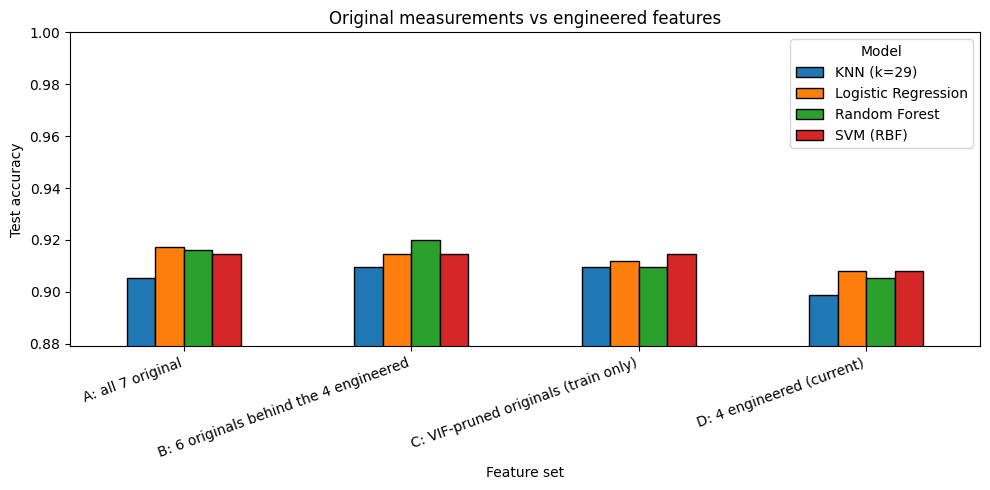

In [149]:
display(fs_results.pivot(index='Feature set', columns='Model', values='CV Acc (mean)').round(4))
display(fs_results.pivot(index='Feature set', columns='Model', values='Test Acc').round(4))

ax = fs_results.pivot(index='Feature set', columns='Model', values='Test Acc').plot(
    kind='bar', figsize=(10, 5), edgecolor='black')
ax.set_ylabel("Test accuracy")
ax.set_ylim(fs_results['Test Acc'].min() - 0.02, 1.0)
ax.set_title("Original measurements vs engineered features")
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

##Feature importance (Permutation, SHAP, fold stability)

In [150]:
from sklearn.inspection import permutation_importance

fitted_models = {
    'Logistic Regression': lr_s2,
    'Random Forest':       rf_s2,
    f'KNN (k={best_k})':   knn_s3,
    'SVM (RBF)':           svm_s2,
}

perm_mean, perm_std = {}, {}
for name, mdl in fitted_models.items():
    r = permutation_importance(mdl, X_test_s2, y_test, scoring='accuracy',
                               n_repeats=30, random_state=42, n_jobs=-1)
    perm_mean[name] = pd.Series(r.importances_mean, index=X_test_s2.columns)
    perm_std[name]  = pd.Series(r.importances_std,  index=X_test_s2.columns)

perm_df = pd.DataFrame(perm_mean)
perm_df.round(4)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(


,Logistic Regression,Random Forest,KNN (k=29),SVM (RBF)
Eccentricity,0.2238,0.2023,0.2073,0.2163
Extent,0.0021,0.0022,-0.0026,-0.0002
Perimeter_Area_Ratio,0.2377,0.2465,0.2326,0.2444
Compactness,0.0035,-0.0030,-0.0009,0.0023


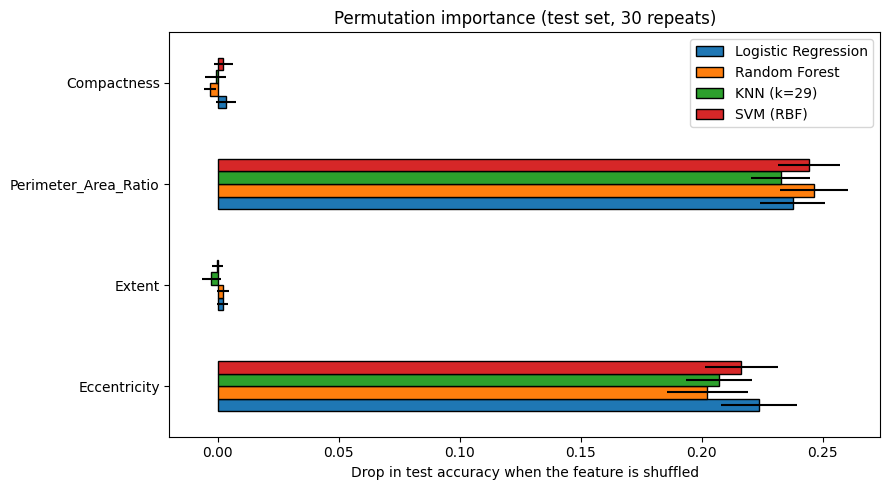

In [151]:
ax = perm_df.plot(kind='barh', figsize=(9, 5), edgecolor='black',
                  xerr=pd.DataFrame(perm_std))
ax.set_xlabel("Drop in test accuracy when the feature is shuffled")
ax.set_title("Permutation importance (test set, 30 repeats)")
plt.tight_layout()
plt.show()

In [152]:
!pip install -q shap

In [153]:
import shap

def positive_class_shap(sv):
    """Return SHAP values for class 1 (Osmancik) regardless of the shap version's output shape."""
    if isinstance(sv, list):
        return sv[1]
    sv = np.asarray(sv)
    return sv[:, :, 1] if sv.ndim == 3 else sv

# Random Forest (tree explainer)
shap_rf = positive_class_shap(shap.TreeExplainer(rf_s2).shap_values(X_test_s2))

# Logistic Regression (linear explainer)
shap_lr = shap.LinearExplainer(lr_s2, X_train_s2).shap_values(X_test_s2)

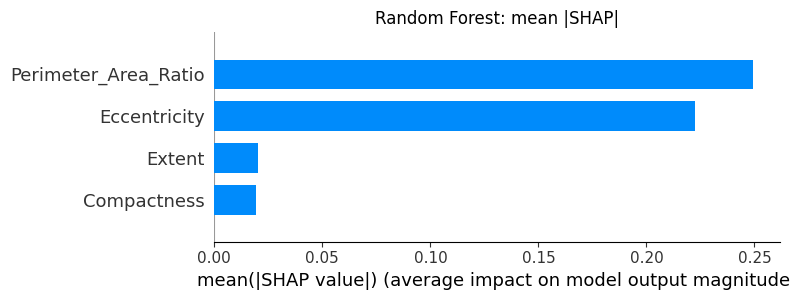

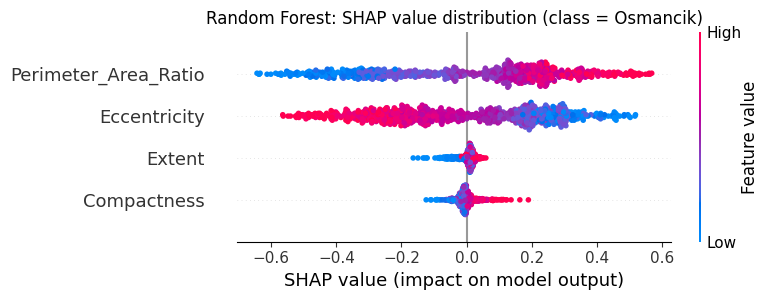

In [154]:
shap.summary_plot(shap_rf, X_test_s2, plot_type='bar', show=False)
plt.title("Random Forest: mean |SHAP|")
plt.tight_layout()
plt.show()

shap.summary_plot(shap_rf, X_test_s2, show=False)
plt.title("Random Forest: SHAP value distribution (class = Osmancik)")
plt.tight_layout()
plt.show()

In [155]:
shap_table = pd.DataFrame({
    'RF mean |SHAP|': np.abs(shap_rf).mean(axis=0),
    'LR mean |SHAP|': np.abs(shap_lr).mean(axis=0),
}, index=X_test_s2.columns)
shap_table['RF rank'] = shap_table['RF mean |SHAP|'].rank(ascending=False).astype(int)
shap_table['LR rank'] = shap_table['LR mean |SHAP|'].rank(ascending=False).astype(int)
shap_table.sort_values('RF rank').round(4)

,RF mean |SHAP|,LR mean |SHAP|,RF rank,LR rank
Perimeter_Area_Ratio,0.2494,2.6621,1,1
Eccentricity,0.2226,2.6452,2,2
Extent,0.0200,0.1030,3,4
Compactness,0.0192,0.4325,4,3


In [156]:
from scipy.stats import spearmanr
from itertools import combinations

fold_imp = {}
for k, (tr, va) in enumerate(cv.split(X_train, y_train), start=1):
    pipe = Pipeline([
        ('prep',  clone(preprocessor_s2)),
        ('model', RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1, **clean_params(grid_rf))),
    ])
    pipe.fit(X_train.iloc[tr], y_train[tr])
    r = permutation_importance(pipe, X_train.iloc[va], y_train[va], scoring='accuracy',
                               n_repeats=20, random_state=42, n_jobs=-1)
    fold_imp[f'Fold {k}'] = pd.Series(r.importances_mean, index=X_train.columns)

fold_imp  = pd.DataFrame(fold_imp)
fold_rank = fold_imp.rank(ascending=False).astype(int)

display(fold_imp.round(4))
display(fold_rank)

,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5
Eccentricity,0.2228,0.2191,0.2211,0.2239,0.2374
Extent,0.0051,0.0020,0.0076,0.0063,-0.0032
Compactness,0.0044,0.0085,0.0087,0.0087,0.0011
Perimeter_Area_Ratio,0.2359,0.2586,0.2676,0.2472,0.2373


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5
Eccentricity,2,2,2,2,1
Extent,3,4,4,4,4
Compactness,4,3,3,3,3
Perimeter_Area_Ratio,1,1,1,1,2


,Mean importance,Std across folds,Mean rank,Rank range
Perimeter_Area_Ratio,0.2493,0.0137,1.2000,1 - 2
Eccentricity,0.2249,0.0072,1.8000,1 - 2
Compactness,0.0063,0.0034,3.2000,3 - 4
Extent,0.0036,0.0043,3.8000,3 - 4


Mean pairwise Spearman correlation of rankings between folds: 0.84


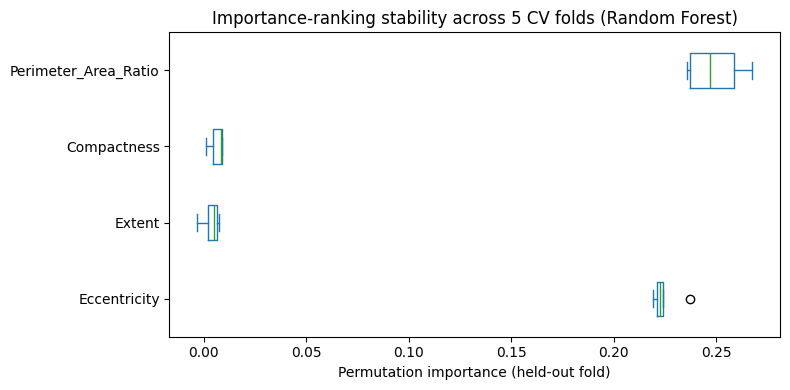

In [157]:
stability = pd.DataFrame({
    'Mean importance': fold_imp.mean(axis=1),
    'Std across folds': fold_imp.std(axis=1),
    'Mean rank':       fold_rank.mean(axis=1),
    'Rank range':      fold_rank.min(axis=1).astype(str) + " - " + fold_rank.max(axis=1).astype(str),
}).sort_values('Mean rank')
display(stability.round(4))

pair_rho = [spearmanr(fold_rank[a], fold_rank[b])[0] for a, b in combinations(fold_rank.columns, 2)]
print("Mean pairwise Spearman correlation of rankings between folds:", round(np.nanmean(pair_rho), 3))

fold_imp.T.plot(kind='box', figsize=(8, 4), vert=False)
plt.xlabel("Permutation importance (held-out fold)")
plt.title("Importance-ranking stability across 5 CV folds (Random Forest)")
plt.tight_layout()
plt.show()

In [158]:
eng_cols = list(X_train.columns)
removal_sets = {'All 4': eng_cols}
for c in eng_cols:
    removal_sets[f'Drop {c}'] = [f for f in eng_cols if f != c]

In [159]:
rem_rows = []
for set_name, cols in removal_sets.items():
    for model_name, make_model in model_factories.items():
        pipe = Pipeline([('prep', make_preprocessor(cols)), ('model', make_model())])
        cvr = cross_validate(pipe, X_train[cols], y_train, cv=cv, scoring='accuracy')
        pipe.fit(X_train[cols], y_train)
        rem_rows.append({
            'Feature set': set_name, 'Model': model_name,
            'CV Acc': cvr['test_score'].mean(), 'CV Std': cvr['test_score'].std(),
            'Test Acc': accuracy_score(y_test, pipe.predict(X_test[cols])),
        })

removal = pd.DataFrame(rem_rows)

In [160]:
cv_piv = removal.pivot(index='Feature set', columns='Model', values='CV Acc').loc[list(removal_sets)]
te_piv = removal.pivot(index='Feature set', columns='Model', values='Test Acc').loc[list(removal_sets)]

display(cv_piv.round(4))
display(cv_piv.sub(cv_piv.loc['All 4'], axis=1).drop(index='All 4').round(4))
display(te_piv.round(4))

Model,KNN (k=29),Logistic Regression,Random Forest,SVM (RBF)
Feature set,,,,
All 4,0.9236,0.9272,0.9275,0.9295
Drop Eccentricity,0.8192,0.8071,0.8189,0.8196
Drop Extent,0.9278,0.9262,0.9268,0.9291
Drop Compactness,0.9177,0.9203,0.9213,0.9239
Drop Perimeter_Area_Ratio,0.7884,0.7904,0.7890,0.7917


Model,KNN (k=29),Logistic Regression,Random Forest,SVM (RBF)
Feature set,,,,
Drop Eccentricity,-0.1043,-0.1201,-0.1086,-0.1099
Drop Extent,0.0043,-0.0010,-0.0007,-0.0003
Drop Compactness,-0.0059,-0.0069,-0.0062,-0.0056
Drop Perimeter_Area_Ratio,-0.1352,-0.1368,-0.1384,-0.1378


Model,KNN (k=29),Logistic Regression,Random Forest,SVM (RBF)
Feature set,,,,
All 4,0.8990,0.9081,0.9055,0.9081
Drop Eccentricity,0.7992,0.7782,0.8058,0.7940
Drop Extent,0.9121,0.9081,0.9029,0.9081
Drop Compactness,0.9068,0.9081,0.9081,0.9055
Drop Perimeter_Area_Ratio,0.7756,0.7717,0.7756,0.7703
